<a href="https://colab.research.google.com/github/farrelrassya/Build-a-Large-Language-Model-From-Scratch/blob/main/02.Working_With_Text_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/farrelrassya/Build-a-Large-Language-Model-From-Scratch/blob/main/02.Working_With_Text_Data.ipynb)

# Chapter 2 -- Working with Text Data

*Companion notebook untuk* Build a Large Language Model (From Scratch) *(Sebastian Raschka, Manning 2024)*
**Technical edition -- kode buku plus beberapa pengukuran tambahan**

Model bahasa tidak pernah membaca huruf. Yang masuk ke dalamnya adalah deretan vektor bilangan riil, dan bab ini membangun jalan dari teks mentah menuju vektor-vektor itu. Jalannya terdiri atas beberapa langkah kecil yang masing-masing mudah diikuti: teks dipecah menjadi token, setiap token diberi nomor (token ID), deretan nomor itu dipotong menjadi pasangan input dan target untuk latihan menebak token berikutnya, lalu setiap nomor diganti dengan vektor yang membawa informasi tentang token itu sekaligus posisinya. Di akhir bab, 32 token pertama sebuah cerpen sudah berubah menjadi tensor berukuran `8 x 4 x 256`: 8 potongan teks, masing-masing 4 token, dan setiap token kini sebuah vektor berisi 256 angka. Itulah bentuk input yang akan diolah modul attention di Chapter 3.

Kode bab diambil dari repo resmi [`rasbt/LLMs-from-scratch`](https://github.com/rasbt/LLMs-from-scratch) (Apache-2.0), dalam urutan buku. Di empat tempat, apa yang tercetak di buku tidak cocok dengan apa yang terjadi saat kodenya dijalankan, dan tempat-tempat itu diberi label Errata #1 sampai #4. Di dua di antaranya (#2 dan #4), kode cetak sampai gagal; versi cetak itu dijalankan apa adanya supaya kita bisa melihat sendiri akibatnya, lalu versi repo dipulihkan. Dua lainnya menyangkut prosa dan output yang tercetak di buku, dan diperiksa dengan sel tambahan. Di beberapa titik lain ada pengukuran yang tidak ada di buku, dengan judul **Under the hood**; bagian ini boleh dilewati kalau hanya ingin mengikuti materi buku. Sel kode yang bukan dari buku atau repo bisa dikenali dari komentar di baris pertamanya: "Sel tambahan", "Errata", "Koreksi Errata", atau "Under the hood".

| Under the hood | Yang kita ukur | Hasil |
|---|---|---|
| 1. Lossy vs lossless (2.5) | Apakah `decode(encode(teks))` mengembalikan teks asli, seberapa sering kata baru muncul di bagian akhir cerita, dan biaya token satu kalimat Inggris vs terjemahan Indonesianya | Tokenizer sederhana kehilangan ke-164 newline cerita, BPE GPT-2 mengembalikan teks persis; 12.69% token di 20% akhir cerita tidak dikenal; kalimat Indonesia butuh 29 token BPE GPT-2, versi Inggrisnya 14 |
| 2. BPE dari nol (2.5) | 500 merge yang dilatih hanya pada satu cerpen, dibandingkan dengan tabel merge GPT-2 | Merge pertamanya, `' t'`, juga merge pertama GPT-2; 99 dari 100 merge awal ada di vocabulary GPT-2 |
| 3. Embedding = one-hot @ W (2.7) | Apakah lookup embedding sama dengan perkalian one-hot, untuk nilai dan gradien, dan berapa harganya | Identik sampai bit terakhir; di run ini versi one-hot sekitar 3,181 kali lebih lambat untuk batch 8 x 256 |
| 4. Posisi dan attention (2.8) | Apa yang dilihat attention mini pada `" man bites dog."` vs `" dog bites man."`, dengan dan tanpa causal mask serta positional embedding | Tanpa mask dan tanpa posisi, kedua kalimat tidak bisa dibedakan; causal mask membedakannya sebagian; positional embedding membuat urutan terlihat |

## Setup

Notebook ini dibuat untuk dijalankan dengan *Run all*. Ia butuh Python 3.10 ke atas dan empat paket: `torch`, `tiktoken`, `requests`, dan `matplotlib`. Sel pertama memeriksa keempatnya dan hanya memasang yang belum ada, langsung ke interpreter yang menjalankan kernel, sehingga runtime yang masih kosong (Colab baru, atau virtual environment baru) tidak berhenti di baris import. Padanan manualnya `pip install torch tiktoken requests matplotlib`. Koneksi internet dibutuhkan untuk dua unduhan: cerpen `the-verdict.txt` di 2.2, dan file BPE GPT-2 yang diambil tiktoken saat `get_encoding("gpt2")` pertama kali dipanggil.

Satu sel sengaja berhenti dengan error, yaitu demonstrasi `KeyError: 'Hello'` di 2.3, yang diambil dari repo apa adanya. Di Colab, *Run all* akan berhenti di sel itu; lanjutkan dengan *Runtime > Run after* dari sel sesudahnya (di JupyterLab: *Run > Run Selected Cell and All Below*). Sel itu juga diberi tag `raises-exception`, sehingga eksekusi otomatis lewat `jupyter nbconvert --execute` atau nbclient mencatat error-nya lalu meneruskan ke sel berikutnya.

In [1]:
# Sel tambahan: cek dependensi untuk runtime segar (aman untuk Run all; hanya memasang yang belum ada)
import importlib.util, subprocess, sys

required = ["torch", "tiktoken", "requests", "matplotlib"]
missing = [pkg for pkg in required if importlib.util.find_spec(pkg) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("python   :", sys.version.split()[0])
print("dicek    :", ", ".join(required))
print("dipasang :", ", ".join(missing) if missing else "tidak ada (semua sudah terpasang)")


python   : 3.13.16
dicek    : torch, tiktoken, requests, matplotlib
dipasang : tidak ada (semua sudah terpasang)


Runtime ini (Python 3.13.16) ternyata sudah membawa keempat paket, jadi tidak ada yang dipasang. Di runtime yang masih kosong, paket yang baru dipasang bisa langsung di-import tanpa me-restart kernel, karena paket itu belum pernah di-import sebelumnya di proses yang sama.

Dua sel berikutnya mencatat lingkungan run. Yang pertama, dari repo, mencetak versi `torch` dan `tiktoken`. Yang kedua, sel tambahan, mencatat platform dan memilih device dengan urutan `cuda`, lalu `mps`, lalu `cpu`.

In [2]:
from importlib.metadata import version

print("torch version:", version("torch"))
print("tiktoken version:", version("tiktoken"))

torch version: 2.11.0+cpu
tiktoken version: 0.14.0


PyTorch di run ini versi 2.11.0, dan akhiran `+cpu` menandakan build yang hanya mendukung CPU. tiktoken-nya versi 0.14.0, jauh lebih baru daripada versi 0.7.0 yang dipakai buku.

Apakah selisih versi sebesar ini bisa mengubah token ID? Data token GPT-2 yang dipakai encoding `gpt2`, yaitu daftar token beserta ID-nya, tidak berubah, karena tiktoken mengunduh file-nya lalu memeriksa sidik jarinya (hash). Tapi pola regex yang lebih dulu memotong teks menjadi kata-kata sebelum dicocokkan dengan daftar token itu, dan daftar token khususnya, ditulis di kode tiktoken sendiri, sehingga secara prinsip bisa berubah antarversi. Karena itu di 2.5 setiap ID dari run ini kita bandingkan langsung dengan angka di buku.

Jawaban singkatnya bisa kita intip sekarang. Output kode yang juga dicetak buku, dari panjang cerita sampai bobot acak dari seed 123 di 2.7, keluar sama di run ini, kecuali di satu tempat di 2.5, yaitu satu token ID beserta hasil decode-nya; di sana kita akan memeriksa apakah versi tiktoken memang penyebabnya. (Angka token ID di beberapa figure buku, misalnya Figure 2.4, memang hanya ilustrasi, jadi wajar kalau berbeda dari ID yang keluar di run ini.)

In [3]:
# Sel tambahan (bukan dari buku): platform builder dan pemilihan device
import platform
import torch

device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available()
          else "cpu")
print("platform       :", platform.platform())
print("python         :", platform.python_version())
print("device tersedia:", device)
print("torch threads  :", torch.get_num_threads())
print("dipakai di bab :", "cpu")


platform       : Linux-6.6.122+-x86_64-with-glibc2.39
python         : 3.13.16
device tersedia: cpu
torch threads  : 1
dipakai di bab : cpu


Platformnya Linux x86_64 dengan Python 3.13.16. Karena PyTorch di sini build khusus CPU, device yang terdeteksi adalah `cpu`. Baris `torch threads` juga memperlihatkan bahwa PyTorch hanya memakai 1 thread CPU di runtime ini.

Untuk bab ini, keduanya bukan masalah. Chapter 2 tidak melatih model apa pun. Operasi tensor paling berat di notebook ini, perkalian one-hot dengan matriks embedding di Under the hood 3, butuh 903.63 ms per panggilan di sini (waktu terbaik dari lima ulangan), masih di bawah satu detik. Bab ini memang sengaja dijalankan di CPU, bahkan kalau GPU tersedia (baris terakhir output, `dipakai di bab`), dengan dua alasan. Pertama, bobot acak di 2.7 dibuat oleh generator bilangan acak CPU dengan `torch.manual_seed(123)`, dan dari generator itulah angka di buku berasal. Kedua, pengukuran waktu di Under the hood 3 lebih mudah dibaca kalau tidak ada pemindahan data antar-device. Variabel `device` tidak dipakai lagi di bab ini; pilihan device baru berpengaruh di bab-bab berikutnya, saat model GPT dijalankan (Chapter 4) dan dilatih (Chapter 5).

## 2.1 Understanding word embeddings

Jaringan saraf hanya bisa bekerja dengan angka. Perkalian matriks, penjumlahan, dan gradien semuanya butuh bilangan riil, sedangkan kata adalah simbol: "eagle" dikurangi "duck" tidak berarti apa-apa. Jadi sebelum masuk ke model, setiap potongan teks harus diwakili oleh sebuah vektor. Menyiapkan vektor-vektor itu adalah langkah pertama dalam membangun LLM, dan itulah isi bab ini.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.1.png" width="700">

**Figure 2.1** Peta buku: tiga tahap, sembilan langkah. Chapter 2 mengerjakan langkah 1 di tahap pertama (persiapan dan sampling data); hasilnya menjadi input langkah 2, mekanisme attention di Chapter 3.

Vektor yang mewakili sepotong teks seperti ini disebut *embedding*. Gagasannya tidak khusus untuk teks. Gambar, audio, dan video juga bisa diubah menjadi vektor oleh sebuah *encoder*, yaitu model yang dilatih untuk satu jenis data tertentu. Karena setiap encoder dilatih sendiri-sendiri, vektor dari encoder audio tidak bermakna apa-apa bagi model teks.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.2.png" width="700">

**Figure 2.2** Tiga jenis data, tiga encoder, satu bentuk output: vektor bilangan riil (di gambar hanya tiga angka per sampel).

Yang di-embed juga bisa berbeda ukurannya. Satu dokumen utuh bisa diwakili satu vektor, seperti yang umum dipakai di *retrieval-augmented generation* (RAG, di luar cakupan buku). GPT bekerja di level yang jauh lebih kecil, yaitu token, karena ia menghasilkan teks token demi token.

Word2Vec adalah contoh klasik bahwa vektor bisa membawa makna. Model ini dilatih menebak konteks sebuah kata dari kata itu sendiri (atau sebaliknya), sehingga kata yang sering muncul dalam konteks serupa berakhir berdekatan di ruang vektor.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.3.png" width="700">

**Figure 2.3** Kalau setiap embedding hanya terdiri dari dua angka, ia bisa digambar sebagai titik: nama burung berkumpul di satu sudut, negara dan ibu kotanya di sudut lain, dan long, longer, longest berderet berdekatan.

GPT tidak meminjam vektor Word2Vec. Embedding-nya adalah bagian dari model itu sendiri: sebuah matriks yang diisi angka acak di awal (kita akan melihatnya di 2.7), lalu disetel selama training bersama bobot lain (Chapter 5), sehingga vektornya menyesuaikan diri dengan data dan tugas GPT. Lebarnya juga jauh lebih dari dua angka. Menurut buku, GPT-2 terkecil (117M atau 125M parameter) memakai 768 angka per token, dan GPT-3 175B memakai 12,288. Vektor yang lebih lebar memberi ruang lebih banyak untuk menyimpan informasi, dengan harga komputasi yang lebih mahal. Notebook ini memakai lebar 3 untuk contoh yang bisa dibaca dengan mata, dan 256 untuk versi yang lebih realistis.

Urutan kerjanya sepanjang bab: teks menjadi token (2.2), token menjadi token ID (2.3 sampai 2.5), deretan ID menjadi pasangan input dan target (2.6), lalu ID menjadi vektor (2.7 dan 2.8). Kita mulai dari memecah teks.

## 2.2 Tokenizing text

Langkah pertama adalah *tokenisasi*: memecah teks menjadi potongan-potongan yang disebut token. Untuk sementara, token kita berupa kata atau satu karakter khusus seperti tanda baca. Di 2.5 kita akan beralih ke token yang bisa lebih kecil dari satu kata.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.4.png" width="700">

**Figure 2.4** Posisi tokenisasi di jalur pemrosesan teks LLM: teks input dipecah menjadi token kata dan tanda baca, lalu diubah menjadi token ID dan embedding. Angka token ID di gambar ini hanya ilustrasi; ID GPT-2 yang sebenarnya untuk kalimat yang sama kita lihat di 2.5.

Bahan latihannya cerpen "The Verdict" karya Edith Wharton. Cerpen ini sudah menjadi domain publik, jadi boleh dipakai untuk melatih LLM, dan repo buku menyediakan salinannya. Buku mengunduhnya dengan `urllib.request.urlretrieve`. Sejak [rasbt/LLMs-from-scratch#867](https://github.com/rasbt/LLMs-from-scratch/pull/867) (Oktober 2025), repo memakai library `requests`, karena `urllib` menimbulkan masalah bagi sebagian pembaca yang memakai VPN. Sel berikut adalah versi repo: file diunduh hanya kalau belum ada di folder kerja.

In [4]:
import os
import requests

if not os.path.exists("the-verdict.txt"):
    url = (
        "https://raw.githubusercontent.com/rasbt/"
        "LLMs-from-scratch/main/ch02/01_main-chapter-code/"
        "the-verdict.txt"
    )
    file_path = "the-verdict.txt"

    response = requests.get(url, timeout=30)
    response.raise_for_status()
    with open(file_path, "wb") as f:
        f.write(response.content)


# The book originally used the following code below
# However, urllib uses older protocol settings that
# can cause problems for some readers using a VPN.
# The `requests` version above is more robust
# in that regard.

"""
import os
import urllib.request

if not os.path.exists("the-verdict.txt"):
    url = ("https://raw.githubusercontent.com/rasbt/"
           "LLMs-from-scratch/main/ch02/01_main-chapter-code/"
           "the-verdict.txt")
    file_path = "the-verdict.txt"
    urllib.request.urlretrieve(url, file_path)
"""

'\nimport os\nimport urllib.request\n\nif not os.path.exists("the-verdict.txt"):\n    url = ("https://raw.githubusercontent.com/rasbt/"\n           "LLMs-from-scratch/main/ch02/01_main-chapter-code/"\n           "the-verdict.txt")\n    file_path = "the-verdict.txt"\n    urllib.request.urlretrieve(url, file_path)\n'

Output di atas bukan hasil unduhan. Sel repo ini diakhiri sebuah string bertanda kutip tiga yang berisi kode `urllib` versi lama, dan Jupyter menampilkan string itu karena ia ekspresi terakhir di sel. Kode di dalam string itu tidak dijalankan. Unduhannya sendiri, lewat `requests`, tidak mencetak apa-apa.

Apakah kode versi buku masih bekerja? Sel tambahan berikut menjalankannya, lalu membandingkan kedua file lewat hash SHA-256, semacam sidik jari file: dua file yang berbeda satu byte pun akan memberi hash yang sama sekali lain. Satu hal sengaja diubah dari kode buku. Hasil unduhannya disimpan ke `the-verdict-urllib.txt`, supaya kalau jaringan bermasalah, file `the-verdict.txt` yang dibaca sel-sel berikutnya tidak ikut rusak.

In [5]:
# Sel tambahan: kode unduhan versi cetak buku (urllib), dijalankan untuk kalibrasi ke file terpisah
import hashlib
import urllib.request

url = ("https://raw.githubusercontent.com/rasbt/"
       "LLMs-from-scratch/main/ch02/01_main-chapter-code/"
       "the-verdict.txt")
file_path = "the-verdict-urllib.txt"     # knob: buku "the-verdict.txt"; dipisah agar file bab tidak tertimpa
sha_requests = hashlib.sha256(open("the-verdict.txt", "rb").read()).hexdigest()
try:
    urllib.request.urlretrieve(url, file_path)
    sha_urllib = hashlib.sha256(open(file_path, "rb").read()).hexdigest()
except Exception as e:                   # kalibrasi saja: kegagalan dicatat, bab tetap jalan
    sha_urllib = f"gagal: {type(e).__name__}: {e}"
print("sha256 via requests:", sha_requests)
print("sha256 via urllib  :", sha_urllib)
print("identik            :", sha_requests == sha_urllib)


sha256 via requests: b41e41a68f0398a3154ae69e2e4c0e2694e17fe0d66730536837f1b01935b31f
sha256 via urllib  : b41e41a68f0398a3154ae69e2e4c0e2694e17fe0d66730536837f1b01935b31f
identik            : True


Kedua jalur menghasilkan file yang identik byte demi byte; hash-nya sama, diawali `b41e41a6`. Jadi kode unduhan versi buku masih berjalan di runtime ini, dan pergantian ke `requests` di repo murni soal ketahanan jaringan, bukan perubahan data. Hash ini sekaligus menjadi sidik jari dataset kita: semua angka di bawah berlaku untuk file dengan hash tersebut.

In [6]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

print("Total number of character:", len(raw_text))
print(raw_text[:99])

Total number of character: 20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


Listing 2.1 di atas membaca seluruh cerpen: 20,479 karakter. Potongan teks di baris kedua output sudah memperlihatkan masalah pertama yang harus dihadapi tokenizer: tanda `--` menempel langsung ke kata di kedua sisinya (`genius--though`, `enough--so`). Memotong di spasi saja tidak akan memisahkannya.

In [7]:
# Sel tambahan: beberapa fakta tentang teks yang dipakai sepanjang bab
print("len(raw_text[:99]) :", len(raw_text[:99]))
print("karakter ke-100    :", repr(raw_text[99]))
print("ASCII murni        :", raw_text.isascii())
print("jumlah newline     :", raw_text.count("\n"))
print("kata (str.split)   :", len(raw_text.split()))
print("jumlah ':' dan ';' :", raw_text.count(":"), raw_text.count(";"))


len(raw_text[:99]) : 99
karakter ke-100    : 'g'
ASCII murni        : True
jumlah newline     : 164
kata (str.split)   : 3634
jumlah ':' dan ';' : 21 22


Sebelum mulai memecah teks, sel di atas mencatat beberapa fakta yang akan berguna nanti.

Yang pertama menyangkut detail kecil di buku (Errata #1). Prosa buku menyebut 100 karakter pertama, padahal `raw_text[:99]` berhenti di indeks 98 dan hanya mencetak 99 karakter. Karakter ke-100 adalah `'g'`, huruf pertama kata "great", sehingga output tadi berakhir di `...so it was no `. Kalau maksudnya memang 100 karakter, kodenya cukup diganti `raw_text[:100]`; dampaknya hanya kosmetik.

Sisanya menyangkut isi cerita. Teks ini seluruhnya ASCII, jadi setiap karakter tepat satu byte. Saat kita membangun tokenizer BPE sendiri di Under the hood 2 (BPE baru dibahas di 2.5), fakta ini membuat BPE level byte pada teks ini sama saja dengan BPE level karakter, sehingga setiap langkahnya bisa dibaca sebagai gabungan karakter biasa. Cerita ini juga memuat 164 karakter baris baru (newline), dan setiap tokenizer harus memutuskan apa yang dilakukan dengan karakter seperti itu.

Angka-angka lainnya menjadi pembanding. Sebanyak 3,634 potongan dari `str.split()`, yang memotong hanya di whitespace, akan kita bandingkan dengan tokenizer regex sebentar lagi. Lalu ada 21 titik dua dan 22 titik koma: dua tanda baca yang kelihatannya sepele, tapi justru keduanya yang nanti membuat versi cetak listing 2.3 gagal pada cerita ini.

Tokenizer pertama kita dibangun hanya dengan `re.split`, fungsi pemecah teks berbasis regex di Python. Ini alat sementara untuk memahami masalahnya; mulai 2.5, pekerjaan ini diserahkan ke tokenizer GPT-2. Kita mulai dari yang paling sederhana: memotong di whitespace. Pola `(\s)` diberi tanda kurung, yang menjadikannya grup penangkap, sehingga whitespace ikut dikembalikan sebagai elemen list, bukan dibuang.

In [8]:
import re

text = "Hello, world. This, is a test."
result = re.split(r'(\s)', text)

print(result)

['Hello,', ' ', 'world.', ' ', 'This,', ' ', 'is', ' ', 'a', ' ', 'test.']


Hasilnya 11 elemen: 6 potongan teks dan 5 spasi. Tanda baca masih menempel di kata (`'Hello,'`, `'world.'`, `'This,'`), sehingga `world.` dan `world` akan dianggap dua token berbeda.

Perhatikan juga bahwa teks sengaja tidak diubah menjadi huruf kecil. Huruf kapital membawa informasi, misalnya awal kalimat atau nama seperti `Gisburn`. Keputusan ini ada harganya: `are` di tengah kalimat dan `Are` di awal kalimat menjadi dua token yang berbeda, sehingga tokenizer bisa mengenal yang satu tanpa mengenal yang lain. Under the hood 1 nanti menemukan contoh nyatanya di cerita ini.

In [9]:
result = re.split(r'([,.]|\s)', text)

print(result)

['Hello', ',', '', ' ', 'world', '.', '', ' ', 'This', ',', '', ' ', 'is', ' ', 'a', ' ', 'test', '.', '']


Koma dan titik kini terpisah, tapi list membengkak menjadi 19 elemen: 6 kata, 4 tanda baca, 5 spasi, dan 4 string kosong `''`. String kosong itu efek samping `re.split`. Tiga di antaranya muncul di antara dua pemisah yang bersebelahan (koma atau titik yang langsung diikuti spasi), dan satu di ujung list karena teks diakhiri pemisah `.`. Spasi dan string kosong sama-sama tidak kita perlukan.

In [10]:
# Strip whitespace from each item and then filter out any empty strings.
result = [item for item in result if item.strip()]
print(result)

['Hello', ',', 'world', '.', 'This', ',', 'is', 'a', 'test', '.']


Tinggal 10 token: 6 kata dan 4 tanda baca. Bentuknya sudah rapi, tapi ada yang dikorbankan. Informasi tentang di mana ada spasi dan di mana ada baris baru kini hilang, dan tidak bisa dipulihkan. Untuk melatih model sederhana itu masih bisa diterima; untuk teks seperti kode Python, yang maknanya bergantung pada indentasi, jelas tidak. Seberapa besar kerugian itu untuk seluruh cerita akan kita ukur di Under the hood 1. Tokenizer BPE di 2.5 menghindari kerugian ini dengan menyimpan whitespace di dalam token itu sendiri.

Teks sungguhan punya lebih banyak jenis tanda baca. Pola regex diperluas dengan tanda tanya, titik dua, titik koma, garis bawah, tanda seru, tanda kutip, kurung, dan `--`, lalu setiap potongan dibersihkan dengan `strip()` dan potongan kosong dibuang.

In [11]:
text = "Hello, world. Is this-- a test?"

result = re.split(r'([,.:;?_!"()\']|--|\s)', text)
result = [item.strip() for item in result if item.strip()]
print(result)

['Hello', ',', 'world', '.', 'Is', 'this', '--', 'a', 'test', '?']


Sepuluh token, persis seperti Figure 2.5. `this--` terpecah menjadi `this` dan `--` karena `--` adalah alternatif tersendiri di pola (`|--|`), dan `?` di akhir kalimat kini berdiri sendiri.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.5.png" width="700">

**Figure 2.5** Hasil sel di atas dalam bentuk gambar: `Hello, world. Is this-- a test?` menjadi 10 token.

Tokenizer ini sudah cukup untuk teks kita. Sekarang ia diterapkan ke seluruh cerita.

In [12]:
preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [item.strip() for item in preprocessed if item.strip()]
print(preprocessed[:30])

['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in']


Sekilas, tiga puluh token pertama sudah terpotong dengan benar. `genius--though` kini menjadi tiga token (`genius`, `--`, `though`), begitu juga `enough--so`, dan koma di `that, in` berdiri sendiri. Di antara tiga puluh token ini, tidak ada lagi yang membawa tanda baca. (Tanda hubung tunggal tidak termasuk pola, jadi kata seperti `palm-trees` di bagian lain cerita tetap satu token.)

In [13]:
print(len(preprocessed))

4690


Seluruh cerita menjadi 4,690 token. Dibanding 3,634 potongan dari `str.split()`, ada 1,056 token tambahan, dan semuanya datang dari tanda baca serta `--` yang kini dipisahkan dari kata; selebihnya, kedua cara memotong di whitespace yang sama.

Token-token ini masih berupa string. Langkah berikutnya adalah memberi setiap token sebuah nomor.

## 2.3 Converting tokens into token IDs

Model tidak bisa bekerja langsung dengan string seperti `'genius'` atau `'--'`. Yang ia butuhkan adalah angka, yang nanti dipakai untuk mengambil vektor embedding. Jembatannya adalah *vocabulary*: daftar semua token unik di data training, diurutkan, lalu masing-masing diberi satu bilangan bulat yang disebut *token ID*.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.6.png" width="700">

**Figure 2.6** Versi mainan dari sel berikut: satu kalimat tanpa tanda baca menghasilkan vocabulary berisi 8 entri. Untuk The Verdict, sel di bawah menghasilkan 1,130.

In [14]:
all_words = sorted(set(preprocessed))
vocab_size = len(all_words)

print(vocab_size)

1130


Dari 4,690 token, hanya 1,130 yang unik. Rata-rata setiap token unik muncul 4,690 / 1,130 = 4.15 kali. Angka sekecil ini wajar untuk satu cerpen, tapi juga menjadi peringatan: vocabulary dari satu cerpen akan cepat bolong begitu bertemu teks lain. Under the hood 1 nanti mengukur seberapa cepat.

In [15]:
vocab = {token:integer for integer,token in enumerate(all_words)}

In [16]:
for i, item in enumerate(vocab.items()):
    print(item)
    if i >= 50:
        break

('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)
('A', 11)
('Ah', 12)
('Among', 13)
('And', 14)
('Are', 15)
('Arrt', 16)
('As', 17)
('At', 18)
('Be', 19)
('Begin', 20)
('Burlington', 21)
('But', 22)
('By', 23)
('Carlo', 24)
('Chicago', 25)
('Claude', 26)
('Come', 27)
('Croft', 28)
('Destroyed', 29)
('Devonshire', 30)
('Don', 31)
('Dubarry', 32)
('Emperors', 33)
('Florence', 34)
('For', 35)
('Gallery', 36)
('Gideon', 37)
('Gisburn', 38)
('Gisburns', 39)
('Grafton', 40)
('Greek', 41)
('Grindle', 42)
('Grindles', 43)
('HAD', 44)
('Had', 45)
('Hang', 46)
('Has', 47)
('He', 48)
('Her', 49)
('Hermia', 50)


Inilah 51 entri pertama vocabulary. Entri 0 sampai 10 seluruhnya tanda baca (`!` sampai `?`), dan kata pertama, `A`, baru muncul di indeks 11.

Kenapa urutannya begitu? `sorted()` mengurutkan string berdasarkan kode karakternya (*code point*), bukan seperti kamus. Semua huruf kapital (A-Z, code point 65-90) datang sebelum semua huruf kecil (a-z, 97-122), sehingga `HAD` (44) dan `Had` (45) mendahului semua kata yang diawali huruf kecil. Tanda baca dengan code point 33 sampai 63 (`!` sampai `?`) mendahului keduanya. Tapi tidak semua tanda baca ada di depan: garis bawah `_` (code point 95), yang juga dipisahkan oleh regex kita, jatuh di antara kata berhuruf kapital dan kata berhuruf kecil.

Bagi tokenizer, urutan ini tidak penting: ID hanyalah label, dan makna setiap token nanti dipelajari lewat embedding. Tapi ada akibat praktisnya. ID di sel-sel berikut bergantung pada aturan pengurutan ini, sehingga vocabulary yang dibangun dengan cara lain akan memberi ID berbeda untuk teks yang sama.

Vocabulary ini dibangun sekali, lalu bisa dipakai untuk memetakan teks apa pun ke token ID, selama kata-katanya ada di dalamnya.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.7.png" width="700">

**Figure 2.7** Vocabulary dibangun sekali dari data training, lalu dipakai ulang untuk teks lain. Teks baru yang memuat kata di luar 1,130 entri itu akan memicu `KeyError: 'Hello'` beberapa sel di bawah.

Untuk membaca output model nanti, kita juga butuh arah sebaliknya: *inverse vocabulary* yang memetakan ID kembali ke token. Listing 2.3 membungkus kedua arah dalam satu kelas. `encode` memecah teks dengan regex yang sama seperti tadi, lalu mengganti setiap token dengan ID-nya. `decode` mengganti setiap ID dengan tokennya, menyambung semuanya dengan spasi, lalu menghapus spasi yang terlanjur muncul sebelum tanda baca.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.8.png" width="700">

**Figure 2.8** Kelas tokenizer bekerja dua arah: `encode` lewat vocabulary dan `decode` lewat inverse vocabulary. Contoh di gambar memakai vocabulary mainan; versi The Verdict ada di sel-sel berikut.

Sel berikut adalah versi repo. Versi yang tercetak di buku berbeda satu detail di regex `encode`, dan akibatnya baru terlihat di Errata #2, sesudah demo ini.

In [17]:
class SimpleTokenizerV1:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s,i in vocab.items()}

    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)

        preprocessed = [
            item.strip() for item in preprocessed if item.strip()
        ]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        # Replace spaces before the specified punctuations
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text

In [18]:
tokenizer = SimpleTokenizerV1(vocab)

text = """"It's the last he painted, you know,"
           Mrs. Gisburn said with pardonable pride."""
ids = tokenizer.encode(text)
print(ids)

[1, 56, 2, 850, 988, 602, 533, 746, 5, 1126, 596, 5, 1, 67, 7, 38, 851, 1108, 754, 793, 7]


Kalimat itu menjadi 21 ID. Beberapa ID berulang mengikuti tokennya: `1` (tanda kutip ganda) muncul di posisi 0 dan 12, `5` (koma) dua kali, dan `7` (titik) dua kali.

Ada satu hal yang tidak terlihat dari daftar ini. String input sebenarnya terdiri dari dua baris: di kode, kalimat kedua dimulai di baris baru dengan indentasi, masih di dalam string bertanda kutip tiga. Baris baru dan indentasi itu hilang begitu saja saat encode.

In [19]:
tokenizer.decode(ids)

'" It\' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.'

Sekarang kita balik arahnya. Hasil decode mirip dengan input, tapi **tidak identik**. Input memuat `"It's`, sedangkan decode menghasilkan `" It' s`: ada spasi sesudah kutip pembuka dan spasi di tengah kontraksi. Baris baru dan indentasi di tengah input juga lenyap. Penyebabnya sudah kita lihat di 2.2: informasi spasi dibuang saat encode. `decode` tidak tahu di mana spasi aslinya berada, jadi ia menyambung semua token dengan spasi, lalu hanya menghapus spasi *sebelum* tanda baca tertentu. Spasi *sesudah* kutip pembuka dan sebelum `s` tidak tertangani. (Kutip luar dan `\'` di output muncul karena sel repo menampilkan hasil sebagai nilai terakhir sel, sehingga Jupyter mencetak `repr`-nya, yaitu bentuk string seperti yang ditulis di kode Python. Buku mencetak tampilan yang sama walaupun kodenya memakai `print`, yang tidak menampilkan kutip luar.)

Buku menyebut decode ini berhasil mengembalikan teks aslinya. Yang sebenarnya kembali adalah deretan token yang sama, bukan string yang sama. Di satu kalimat bedanya tampak kecil; di Under the hood 1 kita mengukurnya di seluruh cerita.

In [20]:
tokenizer.decode(tokenizer.encode(text))

'" It\' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.'

Hasilnya sama persis dengan sel sebelumnya, karena `tokenizer.encode(text)` menghasilkan 21 ID yang sama. Untuk kalimat ini, bolak-balik encode lalu decode berakhir di versi teks yang sudah dinormalisasi, bukan di input aslinya.

Tokenizer ini hanya mengenal token yang pernah muncul di The Verdict. Bagaimana kalau kita memberinya kata lain? Sel berikut berhenti dengan error, dan itu memang disengaja (lihat catatan *Run all* di Setup).

In [21]:
tokenizer = SimpleTokenizerV1(vocab)

text = "Hello, do you like tea. Is this-- a test?"

tokenizer.encode(text)

KeyError: 'Hello'

Hasilnya `KeyError: 'Hello'`, seperti yang diperkirakan buku. Kata `Hello` tidak pernah muncul di The Verdict, jadi `self.str_to_int['Hello']` gagal di token pertama. Teks contoh di repo sedikit lebih panjang daripada di buku, yang hanya memakai `"Hello, do you like tea?"`, tapi error-nya sama karena kegagalan sudah terjadi di token pertama.

Pelajarannya, vocabulary perlu dibangun dari data training yang besar dan beragam, atau tokenizer butuh jalan keluar untuk kata yang tidak dikenal. Bagian 2.4 dan 2.5 membahas dua jalan keluar yang berbeda. Di Colab, lanjutkan dari sel berikut dengan *Runtime > Run after*.

### Errata #2 -- regex `encode` di Listing 2.3 versi cetak tidak memisahkan `:` dan `;`

Sebelum menambal masalah kata yang tidak dikenal, ada satu masalah lain yang tersembunyi di versi cetak listing 2.3. Di halaman buku, `encode` memakai pola `r'([,.?_!"()\']|--|\s)'`, padahal vocabulary di atas dibangun dengan `r'([,.:;?_!"()\']|--|\s)'`. Bedanya hanya dua karakter: titik dua dan titik koma tidak ada di pola cetak. Repo sudah memakai pola yang lengkap, dan demo buku tetap lolos karena kalimat contohnya tidak mengandung `:` atau `;`.

Untuk melihat akibatnya, sel berikut menjalankan kelas versi cetak apa adanya pada teks yang dipakai untuk membangun vocabulary-nya sendiri, yaitu seluruh cerita. Tokenizer yang konsisten seharusnya bisa meng-encode teks ini tanpa masalah. Versi repo disimpan dulu supaya bisa dipulihkan, dan traceback-nya dicetak dengan `traceback.print_exc()` supaya *Run all* tetap berlanjut.

In [22]:
# Errata #2 -- Listing 2.3 persis seperti tercetak di buku (regex encode tanpa ':' dan ';')
import traceback
if "SimpleTokenizerV1_repo" not in globals():   # simpan versi repo sekali saja (aman bila sel diulang)
    SimpleTokenizerV1_repo = SimpleTokenizerV1

class SimpleTokenizerV1:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s,i in vocab.items()}
    def encode(self, text):
        preprocessed = re.split(r'([,.?_!"()\']|--|\s)', text)
        preprocessed = [
            item.strip() for item in preprocessed if item.strip()
        ]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids
    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text

try:
    SimpleTokenizerV1(vocab).encode(raw_text)   # teks training-nya sendiri
except KeyError:
    traceback.print_exc()                       # traceback riil, dicetak agar Run all berlanjut


Traceback (most recent call last):
  File "/tmp/ipykernel_2251/897634947.py", line 23, in <cell line: 0>
    SimpleTokenizerV1(vocab).encode(raw_text)   # teks training-nya sendiri
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^
  File "/tmp/ipykernel_2251/897634947.py", line 15, in encode
    ids = [self.str_to_int[s] for s in preprocessed]
           ~~~~~~~~~~~~~~~^^^
KeyError: 'up;'


Tokenizer versi cetak gagal pada teks training-nya sendiri, dengan `KeyError: 'up;'`: kata `up` yang ditempeli titik koma. Vocabulary hanya mengenal `up` dan `;` sebagai dua token terpisah, karena saat vocabulary dibangun, `;` adalah titik potong. Dengan pola cetak, `;` dan `:` bukan lagi titik potong, sehingga setiap kata yang ditempeli salah satunya berubah menjadi token baru yang tidak pernah ada di vocabulary.

Kesalahan seperti ini tidak terlihat di demo buku, dan langsung muncul begitu teks mengandung titik koma. Kelas versi cetak sudah terlanjur menggantikan versi repo sebelum error terjadi, jadi sel berikut memulihkan versi repo, lalu menghitung seberapa besar masalahnya.

In [23]:
# Koreksi Errata #2: pulihkan versi repo (pola lengkap [,.:;?_!"()\']) lalu ukur
SimpleTokenizerV1 = SimpleTokenizerV1_repo

printed_tokens = [t.strip() for t in re.split(r'([,.?_!"()\']|--|\s)', raw_text) if t.strip()]
unknown_printed = [t for t in printed_tokens if t not in vocab]
print("pola cetak : token tak dikenal =", len(unknown_printed), "->", unknown_printed[:6], "...")

ids_full = SimpleTokenizerV1(vocab).encode(raw_text)
print("versi repo : encode(raw_text) =", len(ids_full), "ID")
print("sama dengan token saat vocab dibangun:", ids_full == [vocab[t] for t in preprocessed])
print("':'/';' di dalam token tak dikenal:", sum(t.count(":") + t.count(";") for t in unknown_printed),
      "dari", raw_text.count(":") + raw_text.count(";"),
      "| sisanya mengikuti kutip penutup:", [raw_text[m.start() - 13:m.start() + 1] for m in re.finditer(r'(?<=")[:;]', raw_text)])


pola cetak : token tak dikenal = 41 -> ['up;', 'eyes:', 'painting;', 'speculations;', 'palm-trees;', 'women:'] ...
versi repo : encode(raw_text) = 4690 ID
sama dengan token saat vocab dibangun: True
':'/';' di dalam token tak dikenal: 41 dari 43 | sisanya mengikuti kutip penutup: ['"interesting":', ' no "effects";']


Dengan pola cetak, 41 token di cerita tidak dikenal (`up;`, `eyes:`, `painting;`, `speculations;`, `palm-trees;`, `women:`, dan seterusnya), dan masing-masing membawa tepat satu `:` atau `;`. Di seluruh teks ada 43 tanda seperti itu (21 titik dua dan 22 titik koma yang kita hitung di 2.2), jadi ada dua yang tidak ikut menjadi token tak dikenal. Keduanya muncul tepat sesudah tanda kutip penutup (`"interesting":` dan `"effects";`). Kutip tetap menjadi titik potong di pola cetak, sehingga kedua tanda itu tersisa sebagai token tunggal `:` dan `;` yang memang ada di vocabulary.

Versi repo meng-encode seluruh cerita menjadi 4,690 ID, dan deretannya sama persis dengan token saat vocabulary dibangun. Begitulah seharusnya: encode dan pembangunan vocabulary memakai pola yang sama. Di situlah akar Errata #2. Pola regex ditulis dua kali, sekali untuk membangun vocabulary dan sekali di dalam kelas, dan di buku kedua salinan itu tidak lagi sama.

## 2.4 Adding special context tokens

Kita kembali ke masalah `Hello`. Tokenizer butuh jalan keluar untuk kata yang tidak dikenal. Selain itu, saat data training nanti terdiri dari banyak dokumen, model juga butuh penanda di mana satu dokumen berakhir dan dokumen berikutnya dimulai. Keduanya diselesaikan dengan *token khusus*, yaitu token yang tidak berasal dari teks tetapi ditambahkan ke vocabulary dengan peran tertentu: `<|unk|>` menggantikan kata di luar vocabulary, dan `<|endoftext|>` memisahkan sumber teks yang tidak berhubungan.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.9.png" width="700">

**Figure 2.9** Dua entri baru di ujung vocabulary. ID di gambar hanya ilustrasi; di vocabulary The Verdict keduanya menjadi `<|endoftext|>` = 1130 dan `<|unk|>` = 1131 (dua sel di bawah).

Kenapa penanda dokumen penting? Data training GPT terdiri dari banyak dokumen yang disambung menjadi satu aliran panjang. Tanpa penanda, akhir satu dokumen dan awal dokumen berikutnya terlihat seperti kelanjutan yang wajar, dan model akan belajar menyambung dua teks yang sebenarnya tidak berhubungan. `<|endoftext|>` di setiap batas memberi tahu model bahwa teks sebelumnya sudah selesai.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.10.png" width="700">

**Figure 2.10** Empat dokumen yang tidak saling berhubungan (laporan olahraga, dongeng, berita pasar saham, kisah pendek) disambung menjadi satu aliran training, dengan `<|endoftext|>` di setiap batas.

In [24]:
all_tokens = sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>", "<|unk|>"])

vocab = {token:integer for integer,token in enumerate(all_tokens)}

In [25]:
len(vocab.items())

1132

Vocabulary kini berisi 1,132 entri: 1,130 token dari cerita ditambah dua token khusus. (Prosa buku di bagian ini sempat menulis `<unk>` tanpa garis tegak; kodenya memakai `<|unk|>`.)

In [26]:
for i, item in enumerate(list(vocab.items())[-5:]):
    print(item)

('younger', 1127)
('your', 1128)
('yourself', 1129)
('<|endoftext|>', 1130)
('<|unk|>', 1131)


Kedua token khusus mendapat dua ID terakhir: `<|endoftext|>` = 1130 dan `<|unk|>` = 1131. Ini terjadi karena keduanya ditambahkan dengan `extend` *sesudah* daftar token diurutkan. Kalau ikut diurutkan, karakter `<` (code point 60) akan menempatkan keduanya di antara `;` (59) dan `?` (63), dan ID setiap token sesudahnya ikut bergeser dua angka; sebagian besar ID yang kita lihat di 2.3 akan berubah.

Listing 2.4 menambahkan satu langkah ke `encode`: setiap token yang tidak ada di vocabulary diganti `<|unk|>` sebelum dipetakan ke ID. Pola di `decode` juga diperluas dengan `:` dan `;`, sehingga spasi sebelum kedua tanda itu ikut dihapus.

In [27]:
class SimpleTokenizerV2:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = { i:s for s,i in vocab.items()}

    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [item.strip() for item in preprocessed if item.strip()]
        preprocessed = [
            item if item in self.str_to_int
            else "<|unk|>" for item in preprocessed
        ]

        ids = [self.str_to_int[s] for s in preprocessed]
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        # Replace spaces before the specified punctuations
        text = re.sub(r'\s+([,.:;?!"()\'])', r'\1', text)
        return text

In [28]:
tokenizer = SimpleTokenizerV2(vocab)

text1 = "Hello, do you like tea?"
text2 = "In the sunlit terraces of the palace."

text = " <|endoftext|> ".join((text1, text2))

print(text)

Hello, do you like tea? <|endoftext|> In the sunlit terraces of the palace.


Untuk mengujinya, dua kalimat yang tidak berhubungan disambung dengan `" <|endoftext|> "`, dengan satu spasi di kedua sisi pemisah, seolah keduanya dua dokumen yang berbeda.

In [29]:
tokenizer.encode(text)

[1131, 5, 355, 1126, 628, 975, 10, 1130, 55, 988, 956, 984, 722, 988, 1131, 7]

Hasilnya 16 ID, dan kali ini tidak ada error. `1130` muncul sekali, sebagai pemisah dokumen. `1131` muncul dua kali: untuk `Hello` di awal dan untuk `palace` di akhir. Kata yang tidak dikenal tidak lagi membuat tokenizer berhenti; semuanya dipetakan ke satu ID bersama.

In [30]:
tokenizer.decode(tokenizer.encode(text))

'<|unk|>, do you like tea? <|endoftext|> In the sunlit terraces of the <|unk|>.'

Decode memperlihatkan harganya. `Hello` dan `palace` kembali sebagai `<|unk|>`, dan informasinya hilang untuk selamanya. Karena semua kata yang tidak dikenal berbagi ID 1131, nanti mereka juga berbagi satu vektor yang sama, sehingga model tidak bisa membedakan "palace" dari "Hello". Tokenizer ini tidak pernah gagal lagi, tapi sebagai gantinya ia diam-diam membuang sebagian teks.

Dua token khusus ini bukan satu-satunya konvensi. Sebagian tokenizer lain memakai `[BOS]` (awal sekuens), `[EOS]` (akhir sekuens), dan `[PAD]` (pengisi, supaya teks dalam satu batch sama panjang). Tokenizer GPT-2 tidak memakai ketiganya. Ia hanya punya `<|endoftext|>` (ID 50256), yang merangkap pemisah dokumen dan, di Chapter 6 dan 7, token pengisi. Menurut buku, token mana pun bisa dipakai sebagai pengisi, karena posisi pengisi nanti dikecualikan lewat mask saat training.

Tokenizer GPT-2 juga tidak punya `<|unk|>`. Untuk kata yang tidak dikenal, ia memakai cara yang sama sekali lain, dan itulah topik bagian berikut: kata dipecah menjadi potongan-potongan yang lebih kecil.

## 2.5 Byte pair encoding

Kedua tokenizer sejauh ini punya kelemahan yang sama: vocabulary-nya berisi kata utuh, sehingga kata baru hanya bisa ditolak (`KeyError`) atau dihapus (`<|unk|>`). Tokenizer GPT-2 mengambil jalan lain, yaitu *byte pair encoding* (BPE); menurut buku, tokenizer BPE juga dipakai untuk melatih GPT-3 dan model awal di balik ChatGPT. Vocabulary BPE berisi kata utuh sekaligus potongan kata, sampai ke byte tunggal (untuk teks ASCII seperti The Verdict, satu byte sama dengan satu karakter), sehingga kata apa pun bisa disusun dari potongan yang dikenal.

Cara kerja BPE akan kita bangun sendiri di Under the hood 2. Untuk sekarang, buku memakai [`tiktoken`](https://github.com/openai/tiktoken), library open source dari OpenAI yang intinya ditulis dalam Rust. Kode buku ditulis untuk tiktoken 0.7.0.

In [31]:
# pip install tiktoken

In [32]:
import importlib
import tiktoken

print("tiktoken version:", importlib.metadata.version("tiktoken"))

tiktoken version: 0.14.0


Run ini memakai tiktoken 0.14.0. Sel pencetak versi ini diambil dari repo, dan versi cetaknya di buku sedikit berbeda: buku menulis `from importlib.metadata import version`, sedangkan repo memakai `import importlib` lalu memanggil `importlib.metadata.version(...)`. Perbedaan sekecil ini ternyata ada akibatnya. Sel tambahan berikut menjalankan kedua varian di interpreter Python biasa, di luar notebook, ditambah varian repo sesudah modul kernel Jupyter dimuat.

In [33]:
# Sel tambahan: varian sel versi di interpreter Python biasa (subprocess segar)
import os, subprocess, sys
env = {**os.environ, "PYTHON_COLORS": "0"}   # traceback tanpa warna ANSI, sama di terminal dan kernel
snippets = {
    "repo, skrip biasa      ": "import importlib; import tiktoken; print(importlib.metadata.version('tiktoken'))",
    "repo, setelah ipykernel": "import ipykernel.kernelapp, importlib, tiktoken; print(importlib.metadata.version('tiktoken'))",
    "buku, skrip biasa      ": "from importlib.metadata import version; print(version('tiktoken'))",
}
for label, snippet in snippets.items():
    r = subprocess.run([sys.executable, "-c", snippet], capture_output=True, text=True, env=env)
    print(f"{label} -> {(r.stdout or r.stderr).strip().splitlines()[-1]}")
print("importlib.metadata sudah dimuat di proses notebook ini:", "importlib.metadata" in sys.modules)


repo, skrip biasa       -> AttributeError: module 'importlib' has no attribute 'metadata'
repo, setelah ipykernel -> 0.14.0
buku, skrip biasa       -> 0.14.0
importlib.metadata sudah dimuat di proses notebook ini: True


Di skrip atau REPL Python biasa, varian repo gagal dengan `AttributeError: module 'importlib' has no attribute 'metadata'`, karena `import importlib` (begitu pula `import tiktoken`) tidak otomatis memuat submodul `importlib.metadata`. Di Jupyter dan Colab, sel repo tetap jalan, bahkan sebagai sel pertama di kernel baru, karena modul kernel (`ipykernel`) sudah memuat `importlib.metadata` saat kernel dimulai; baris kedua output memperlihatkannya. Varian buku jalan di semua kondisi.

Jadi kali ini arahnya terbalik: kode repo-lah yang diam-diam bergantung pada lingkungan. Ia aman di notebook, tapi gagal begitu disalin ke skrip Python biasa.

Kembali ke materi buku. Tokenizer GPT-2 dimuat dengan `tiktoken.get_encoding("gpt2")`, lalu diuji pada teks yang mirip dengan uji di 2.4: dua kalimat yang dipisahkan `<|endoftext|>`, hanya saja `the palace` di ujungnya diganti `someunknownPlace`, kata karangan yang jelas tidak ada di vocabulary The Verdict. Argumen `allowed_special={"<|endoftext|>"}` perlu ditulis karena secara bawaan tiktoken menolak meng-encode teks yang memuat string token khusus; akibat lupa menuliskannya akan kita lihat di Errata #4.

In [34]:
tokenizer = tiktoken.get_encoding("gpt2")

In [35]:
text = (
    "Hello, do you like tea? <|endoftext|> In the sunlit terraces"
     "of someunknownPlace."
)

integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})

print(integers)

[15496, 11, 466, 345, 588, 8887, 30, 220, 50256, 554, 262, 4252, 18250, 8812, 2114, 1659, 617, 34680, 27271, 13]


Teks uji itu menjadi 20 ID, dan 19 di antaranya sama dengan yang dicetak buku. Bedanya ada di indeks 15: run ini menghasilkan `1659`, sedangkan buku mencetak `286`. Tersangka pertama yang terpikir adalah versi tiktoken, yang di run ini jauh lebih baru daripada versi buku. Sebelum menyimpulkan apa-apa, kita lihat dulu hasil decode-nya.

In [36]:
strings = tokenizer.decode(integers)

print(strings)

Hello, do you like tea? <|endoftext|> In the sunlit terracesof someunknownPlace.


Decode memberi petunjuknya: `terracesof`, tanpa spasi. Di kode, teks ditulis sebagai dua string yang bersebelahan di dalam tanda kurung. Python menyambung string seperti itu tanpa pemisah apa pun (*implicit concatenation*), dan string pertama berakhir di `terraces` tanpa spasi penutup. BPE mengembalikan persis apa yang diberikan kepadanya, termasuk salah ketik. Buku mencetak `terraces of`. Sel tambahan berikut memeriksa teks mana yang sebenarnya menghasilkan output buku.

In [37]:
# Sel tambahan (Errata #3): tambahkan satu spasi yang hilang, bandingkan dengan output cetak buku
book_ids = [15496, 11, 466, 345, 588, 8887, 30, 220, 50256, 554, 262, 4252, 18250,
            8812, 2114, 286, 617, 34680, 27271, 13]
text_spaced = (
    "Hello, do you like tea? <|endoftext|> In the sunlit terraces "
     "of someunknownPlace."
)
ids_spaced = tokenizer.encode(text_spaced, allowed_special={"<|endoftext|>"})
print("kode cetak    == output buku:", integers == book_ids,
      "| indeks beda:", [i for i, (a, b) in enumerate(zip(integers, book_ids)) if a != b])
print("teks berspasi == output buku:", ids_spaced == book_ids)
print("token 13-16 kode cetak :", [tokenizer.decode([i]) for i in integers[13:17]])
print("token 13-16 berspasi   :", [tokenizer.decode([i]) for i in ids_spaced[13:17]])
words_text = [t.strip() for t in re.split(r'([,.:;?_!"()\']|--|\s)', text) if t.strip()]
print("token regex di luar vocab 2.4 (1132):", [t for t in words_text if t not in vocab])


kode cetak    == output buku: False | indeks beda: [15]
teks berspasi == output buku: True
token 13-16 kode cetak : [' terr', 'aces', 'of', ' some']
token 13-16 berspasi   : [' terr', 'aces', ' of', ' some']
token regex di luar vocab 2.4 (1132): ['Hello', 'terracesof', 'someunknownPlace']


Jadi **output tiktoken yang tercetak di buku tidak dihasilkan oleh kode yang tercetak di sebelahnya**; inilah Errata #3. Kode di buku dan di repo sama-sama tanpa spasi sesudah `terraces`, sehingga hasilnya `' terr' + 'aces' + 'of'`, dengan `of` tanpa spasi pembuka (ID 1659). Dengan satu spasi tambahan, tokennya menjadi `' terr' + 'aces' + ' of'` (ID 286), dan ke-20 ID cocok dengan buku. Karena tiktoken 0.14.0 yang sama menghasilkan ke-20 ID buku begitu spasinya ditambahkan, selisih tadi bukan soal versi tiktoken. (Output yang tersimpan di notebook repo juga berisi `1659`, sesuai dengan kodenya yang sama-sama tanpa spasi.) Perbaikannya cukup menambahkan spasi di akhir string pertama (`"... terraces "`).

Pelajarannya lebih luas daripada sebuah salah ketik. Untuk teks biasa, BPE tidak mengenal kondisi "tidak dikenal": setiap kata, termasuk typo, dipecah menjadi potongan yang ada di vocabulary. (Satu-satunya input yang ditolak tiktoken di bab ini adalah string token khusus tanpa `allowed_special`, seperti disebut sebelum teks uji tadi.) Akibatnya typo seperti `terracesof` lolos tanpa error, dan baru ketahuan kalau ID-nya dibandingkan dengan acuan. Tokenizer berbasis vocabulary kata justru akan menangkapnya. Baris terakhir output memperlihatkan bahwa `terracesof` termasuk tiga token di luar vocabulary 1,132 entri tadi, bersama `Hello` dan `someunknownPlace`. SimpleTokenizerV1 akan berhenti dengan `KeyError` (pada teks ini sudah lebih dulu di `'Hello'`), sedangkan SimpleTokenizerV2 akan menyembunyikannya sebagai `<|unk|>`.

Buku mencatat dua hal tentang hasil BPE tadi. Pertama, `<|endoftext|>` mendapat ID yang besar, 50256. Kedua, `someunknownPlace` bisa di-encode dan di-decode tanpa `<|unk|>`. Sel berikut memeriksa keduanya, sekaligus mencari ID yang sebenarnya untuk kalimat contoh di Figure 2.4.

In [38]:
# Sel tambahan: ukuran vocab GPT-2, posisi <|endoftext|>, dan ID riil kalimat Figure 2.4
print("n_vocab                :", tokenizer.n_vocab)
print("eot_token              :", tokenizer.eot_token, repr(tokenizer.decode([tokenizer.eot_token])))
print("rank token biasa       :", min(tokenizer._mergeable_ranks.values()), "..",
      max(tokenizer._mergeable_ranks.values()))
fig_ids = tokenizer.encode("This is an example.")
print("'This is an example.'  :", fig_ids, [tokenizer.decode([i]) for i in fig_ids])
print("' someunknownPlace'    :", tokenizer.encode(" someunknownPlace"),
      [tokenizer.decode([i]) for i in tokenizer.encode(" someunknownPlace")])


n_vocab                : 50257
eot_token              : 50256 '<|endoftext|>'
rank token biasa       : 0 .. 50255
'This is an example.'  : [1212, 318, 281, 1672, 13] ['This', ' is', ' an', ' example', '.']
' someunknownPlace'    : [617, 34680, 27271] [' some', 'unknown', 'Place']


Vocabulary GPT-2 berisi 50,257 token. Di tiktoken, ID token biasa disebut *rank* (baris ketiga output), karena angka itu juga menyatakan urutan. Rank 0 sampai 255 adalah 256 byte tunggal, bahan dasar BPE. Rank 256 sampai 50255 adalah 50,000 token hasil *merge*, yaitu penggabungan dua potongan yang sering bersebelahan menjadi satu token baru, diurutkan menurut kapan token itu dibentuk saat tokenizer dilatih: makin kecil rank-nya, makin awal ia dibentuk. Cara kerjanya kita bangun sendiri di Under the hood 2. Satu token khusus, `<|endoftext|>`, ditambahkan sesudah semuanya dan memegang ID terakhir, 50256. Itulah sebabnya ID-nya begitu besar.

Kalimat `"This is an example."` menjadi `[1212, 318, 281, 1672, 13]`. Figure 2.4 memakai `40134 2052 133 389 12`, jadi angka di gambar itu memang hanya ilustrasi; angka ilustratif yang sama dipakai lagi di Figure 2.15 dan 2.19. Potongan tokennya juga menarik: `'This'`, `' is'`, `' an'`, `' example'`, `'.'`. Spasi tidak dibuang seperti di tokenizer regex kita, melainkan menempel di depan token berikutnya. Itulah yang memungkinkan decode GPT-2 mengembalikan teks persis seperti aslinya.

Terakhir, `someunknownPlace` dipecah menjadi `' some' + 'unknown' + 'Place'` (617, 34680, 27271), tiga potongan yang masing-masing ada di vocabulary. Tidak perlu `<|unk|>`: kata yang tidak dikenal cukup dirakit dari bagian-bagian yang dikenal.

### Under the hood 1 -- Seberapa lossy tokenizer sederhana?

Sejauh ini kita sudah bertemu tiga klaim buku tentang tokenizer: decode SimpleTokenizer mengembalikan teks asli (2.3), vocabulary kecil tidak tahan terhadap teks baru (2.3 dan 2.4), dan BPE bisa meng-encode kata apa pun tanpa `<|unk|>` (2.5). Ketiganya bisa diukur langsung, tanpa training.

Klaim pertama kita uji pada seluruh 20,479 karakter cerita, bukan hanya satu kalimat: apakah `decode(encode(x))` benar-benar sama dengan `x`? Untuk klaim kedua, vocabulary dibangun dari 80% token awal cerita, lalu diuji pada 20% sisanya. Penulis, gaya, dan ceritanya sama, jadi ini kondisi paling ramah yang mungkin bagi vocabulary kecil. Klaim ketiga diuji dengan teks yang sama sekali lain: satu kalimat bahasa Inggris dan terjemahan Indonesianya, yang ditulis khusus untuk tes ini. Ini hanya satu pasang contoh, bukan sampel korpus. Di output, ketiga pengukuran itu diberi label (a), (b), dan (c).

In [39]:
# Under the hood 1 -- lossy vs lossless (kode orisinal, bukan dari buku)
import collections, difflib

simple = SimpleTokenizerV2(vocab)          # vocab 1132 token dari 2.4
bpe = tiktoken.get_encoding("gpt2")

# (a) round trip di seluruh cerita
rt_simple = simple.decode(simple.encode(raw_text))
rt_bpe = bpe.decode(bpe.encode(raw_text))
diffs = [op for op in difflib.SequenceMatcher(None, raw_text, rt_simple, autojunk=False).get_opcodes()
         if op[0] != "equal"]
kinds = collections.Counter((raw_text[i1:i2], rt_simple[j1:j2]) for _, i1, i2, j1, j2 in diffs)
print("(a) round trip seluruh cerita")
print(f"    SimpleTokenizerV2 identik: {rt_simple == raw_text} | karakter {len(raw_text)} -> {len(rt_simple)}"
      f" | newline {raw_text.count(chr(10))} -> {rt_simple.count(chr(10))} | blok beda {len(diffs)}")
print("    jenis beda terbanyak (asli -> decode, jumlah):")
for (a, b), n in kinds.most_common(5):
    print(f"        {a!r:>8} -> {b!r:<6} {n}")
print(f"    '--' di teks asli: {raw_text.count('--')} | ' -- ' (berspasi) di hasil decode: {rt_simple.count(' -- ')}")
print(f"    GPT-2 BPE identik        : {rt_bpe == raw_text}")

# (b) OOV: vocabulary dari 80% token awal, diuji pada 20% sisanya
cut = int(0.8 * len(preprocessed))
seen, held_out = set(preprocessed[:cut]), preprocessed[cut:]
oov = [t for t in held_out if t not in seen]
print(f"(b) vocab dari {cut} token awal ({len(seen)} tipe), diuji pada {len(held_out)} token akhir")
print(f"    OOV {len(oov)} token = {len(oov) / len(held_out):.2%} ({len(set(oov))} tipe unik),"
      f" contoh {sorted(set(oov))[:6]}")
print("    bentuk huruf kecil 'are' / 'at' ada di vocab 80%:", "are" in seen, "/", "at" in seen)

# (c) satu pasang kalimat contoh: Inggris vs terjemahan Indonesianya
sentences = {"EN": "The model learns to predict the next word from the words before it.",
             "ID": "Model belajar memprediksi kata berikutnya dari kata-kata sebelumnya."}
ntok, tpw = {}, {}
for lang, s in sentences.items():
    ids_simple, ids_bpe = simple.encode(s), bpe.encode(s)
    ntok[lang], tpw[lang] = len(ids_bpe), len(ids_bpe) / len(s.split())
    print(f"(c) {lang}: {len(s.split())} kata | Simple {len(ids_simple)} token,"
          f" <|unk|> {ids_simple.count(vocab['<|unk|>'])} | BPE {len(ids_bpe)} token"
          f" = {tpw[lang]:.2f} token/kata, round trip {bpe.decode(ids_bpe) == s}")
print(f"    isi yang sama, token BPE ID/EN: {ntok['ID']}/{ntok['EN']} = {ntok['ID'] / ntok['EN']:.2f}x")
print("    potongan BPE kalimat ID:", [bpe.decode([i]) for i in bpe.encode(sentences["ID"])])


(a) round trip seluruh cerita
    SimpleTokenizerV2 identik: False | karakter 20479 -> 20684 | newline 164 -> 0 | blok beda 526
    jenis beda terbanyak (asli -> decode, jumlah):
              '' -> ' '    347
          '\n\n' -> ' '    41
          '\n\n' -> ''     39
              '' -> '"'    30
             '"' -> ''     30
    '--' di teks asli: 97 | ' -- ' (berspasi) di hasil decode: 94
    GPT-2 BPE identik        : True
(b) vocab dari 3752 token awal (1020 tipe), diuji pada 938 token akhir
    OOV 119 token = 12.69% (110 tipe unik), contoh ['Are', 'At', 'Begin', 'Devonshire', 'Greek', 'Hang']
    bentuk huruf kecil 'are' / 'at' ada di vocab 80%: True / True
(c) EN: 13 kata | Simple 14 token, <|unk|> 4 | BPE 14 token = 1.08 token/kata, round trip True
(c) ID: 8 kata | Simple 9 token, <|unk|> 8 | BPE 29 token = 3.62 token/kata, round trip True
    isi yang sama, token BPE ID/EN: 29/14 = 2.07x
    potongan BPE kalimat ID: ['Model', ' bel', 'aj', 'ar', ' mem', 'pred', 'i', 'ks', 'i

Teks yang kembali dari SimpleTokenizerV2 berbeda dari aslinya di 526 tempat, dan panjangnya berubah dari 20,479 menjadi 20,684 karakter. Ke-164 newline lenyap tanpa sisa, sehingga struktur paragraf hilang total: sebagian `\n\n` berubah menjadi spasi, sebagian lagi hilang begitu saja.

Jenis perbedaan yang paling sering (347 kali) adalah spasi yang disisipkan, dan sumber terbesarnya `--`. Decode menyambung token dengan spasi dan tidak pernah menghapus spasi di sekitar `--`, sehingga dari 97 kemunculan `--` di teks asli, 94 kembali sebagai ` -- ` berspasi: `genius--though` menjadi `genius -- though`. Sisanya antara lain muncul di dalam kontraksi (`It' s`) dan sesudah kutip pembuka, seperti yang kita lihat di 2.3, serta di sekitar garis bawah `_`, yang dipakai cerita sebagai penanda huruf miring: `_not_` kembali sebagai `_ not _`, karena `_` juga tidak termasuk tanda baca yang spasi sebelumnya dihapus decode. (Pasangan `'"' -> ''` dan `'' -> '"'` di output adalah cara `difflib` mencatat tanda kutip yang bergeser terhadap spasi di sekitarnya.)

GPT-2 BPE, sebaliknya, mengembalikan ke-20,479 karakter tanpa satu pun perbedaan. Jadi klaim buku di 2.3 hanya benar kalau "teks asli" berarti deretan kata; di level string, klaim itu tidak berlaku, dan selisihnya bisa diukur.

Bahkan di dalam cerita yang sama, vocabulary kecil cepat bolong. Vocabulary dari 3,752 token pertama berisi 1,020 jenis token, dan 119 dari 938 token terakhir tidak ada di dalamnya: 12.69%, kira-kira satu dari delapan token. Di antara token yang tidak dikenal ada `Are` dan `At`, padahal `are` dan `at` sudah ada di vocabulary 80% tadi; hanya bentuk berhuruf kapitalnya yang belum pernah muncul. Inilah harga keputusan untuk tidak mengubah teks menjadi huruf kecil di 2.2. Bagi BPE, masalah ini tidak ada, karena kata apa pun bisa dirakit dari potongan yang lebih kecil.

Teks yang sama sekali lain memperlihatkan dua hal sekaligus. Kalimat Inggris 13 kata sudah menghasilkan 4 `<|unk|>` di SimpleTokenizerV2, dan di kalimat Indonesia, 8 dari 8 kata menjadi `<|unk|>`; hanya titik di ujungnya yang dikenali. BPE meng-encode keduanya tanpa `<|unk|>` dan mengembalikan keduanya dengan sempurna. Tapi biayanya timpang: isi yang sama butuh 14 token dalam bahasa Inggris dan 29 token dalam bahasa Indonesia, 2.07 kali lebih banyak. Per kata, angkanya 1.08 dan 3.62 token, karena kalimat Indonesia memakai lebih sedikit kata yang lebih panjang. `belajar` terpotong menjadi `' bel' + 'aj' + 'ar'`, dan `memprediksi` menjadi lima potongan.

Satu pasang kalimat tentu tidak cukup untuk menyimpulkan rasio umum antarbahasa, apalagi "biaya" bahasa Indonesia secara keseluruhan; untuk itu dibutuhkan korpus paralel. Yang diperlihatkan pasangan ini lebih sempit, tapi tetap berguna. GPT-2 sendiri, menurut paper-nya, dilatih pada teks web berbahasa Inggris (WebText). Vocabulary BPE yang dipelajari dari satu jenis teks bisa memotong teks dari jenis lain menjadi potongan yang jauh lebih kecil, seperti `belajar` yang menjadi tiga potongan, dan efek itu bisa diukur dengan cara yang sama untuk data apa pun.

### Exercise 2.1 -- BPE untuk kata yang tidak dikenal

Latihan pertama bab ini menguji klaim tadi dengan string karangan yang bukan kata bahasa Inggris: encode `"Akwirw ier"` dengan tokenizer BPE, decode setiap ID satu per satu untuk mereproduksi Figure 2.11, lalu decode seluruh deretan ID untuk memeriksa apakah input asli kembali utuh.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.11.png" width="700">

**Figure 2.11** Pecahan `"Akwirw ier"` versi buku: enam potongan, masing-masing satu ID GPT-2. Sel-sel di bawah mereproduksinya.

Sel-sel berikut diambil dari solusi resmi (`exercise-solutions.ipynb` di repo). Di sana, enam sel satu baris (sel 8 sampai 13) meng-encode setiap potongan secara terpisah; di sini keenamnya dipadatkan menjadi satu sel. Sel itu juga membawa dua baris di ujungnya yang bukan bagian dari solusi resmi: pencarian rank beberapa pasangan di tabel merge GPT-2, yang gunanya akan terlihat sebentar lagi.

In [40]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

In [41]:
integers = tokenizer.encode("Akwirw ier")
print(integers)

[33901, 86, 343, 86, 220, 959]


Enam ID, `[33901, 86, 343, 86, 220, 959]`, sama dengan Figure 2.11.

In [42]:
for i in integers:
    print(f"{i} -> {tokenizer.decode([i])}")

33901 -> Ak
86 -> w
343 -> ir
86 -> w
220 ->  
959 -> ier


Pemetaannya `Ak`, `w`, `ir`, `w`, spasi, `ier`, persis seperti di gambar. Dua hal patut diperhatikan. `w` muncul dua kali dengan ID yang sama (86), karena potongan yang sama selalu mendapat ID yang sama. Dan spasi berdiri sendiri sebagai token 220, alih-alih menempel di depan `ier` seperti `' is'` dan `' an'` tadi. Kenapa begitu? Dua baris tambahan di sel berikut mencari jawabannya di tabel merge GPT-2.

In [43]:
# Dipadatkan dari exercise-solutions.ipynb sel 8-13 (enam panggilan tokenizer.encode, satu per sel)
for piece in ["Ak", "w", "ir", "w", " ", "ier"]:
    print(f"{piece!r:>6} -> {tokenizer.encode(piece)}")

# Tambahan builder: rank merge yang relevan (rank lebih kecil = digabung lebih dulu)
gpt2_rank = tokenizer._mergeable_ranks
print({s: gpt2_rank.get(s.encode()) for s in ["er", "ie", "ier", " i", " ier"]})


  'Ak' -> [33901]
   'w' -> [86]
  'ir' -> [343]
   'w' -> [86]
   ' ' -> [220]
 'ier' -> [959]
{'er': 263, 'ie': 494, 'ier': 959, ' i': 1312, ' ier': None}


Setiap potongan, kalau di-encode sendirian, kembali ke ID tunggal yang sama, jadi pemetaan ini konsisten di kedua arah. Baris terakhir menjelaskan nasib `" ier"`. Sebelum BPE bekerja, tokenizer GPT-2 memotong teks menjadi kata-kata dengan spasi menempel di depannya, sehingga BPE menerima potongan `" ier"`: empat byte, `' '`, `i`, `e`, `r`. Lalu BPE berulang kali menggabungkan pasangan bersebelahan yang rank-nya paling kecil, yaitu yang dipelajari paling awal saat training tokenizer:

1. Pasangan yang tersedia adalah `' ' + i` (rank 1312), `i + e` (494), dan `e + r` (263). Rank 263 paling kecil, jadi `er` digabung lebih dulu: `[' ', 'i', 'er']`.
2. Kini `i + er` (rank 959) bersaing dengan `' ' + i` (rank 1312). Rank 959 menang, hasilnya `[' ', 'ier']`.
3. `' ier'` tidak ada di tabel (`None`), jadi proses berhenti, dan spasi tersisa sebagai token 220 sendiri.

Spasi tidak menempel ke `ier` bukan karena aturan khusus, tapi karena gabungan `' ier'` memang tidak ada di vocabulary GPT-2.

In [44]:
tokenizer.decode([33901, 86, 343, 86, 220, 959])

'Akwirw ier'

`'Akwirw ier'` kembali utuh, termasuk spasinya. Latihan terjawab: string karangan yang tidak ada utuh di vocabulary GPT-2 dipecah menjadi enam potongan yang semuanya ada di vocabulary, dan decode merakitnya kembali tanpa kehilangan apa pun.

Tapi dari mana tabel merge dan rank-rank tadi berasal? Itulah yang kita bangun berikutnya.

### Under the hood 2 -- BPE dari nol di The Verdict

Buku tidak mengimplementasikan BPE; ia hanya meringkas idenya. Mulai dari karakter tunggal, lalu berulang kali gabungkan pasangan yang paling sering bersebelahan menjadi token baru, misalnya `d` dan `e` menjadi `de`. Setiap penggabungan, atau merge, menambah satu token ke vocabulary, dan urutan merge itulah rank yang kita pakai di Exercise 2.1: merge pertama mendapat rank terkecil.

Algoritma sesederhana ini cukup murah untuk dijalankan sendiri. Sel berikut melatih BPE level byte dalam sekitar 40 baris kode, hanya pada The Verdict, sebanyak 500 merge. Seperti di GPT-2, teks lebih dulu dipotong dengan regex (*pre-tokenisasi*) menjadi kontraksi (`'s`, `'t`, `'re`, ...), kata dengan spasi menempel di depannya, angka, tanda baca, dan whitespace, dan merge tidak pernah melewati batas potongan ini. Polanya adalah versi ASCII dari pola GPT-2, yang memberi potongan yang sama untuk teks ASCII murni seperti The Verdict.

Hasilnya lalu dibandingkan dengan tabel merge GPT-2 asli lewat `tokenizer._mergeable_ranks`, atribut privat tiktoken: rank 0 sampai 255 untuk byte tunggal, rank 256 untuk merge pertama GPT-2, dan seterusnya. Pertanyaannya, seberapa mirip hasil dari 20 kB teks dengan tabel merge milik GPT-2, model yang menurut paper-nya dilatih pada sekitar 40 GB teks web (WebText)?

In [45]:
# Under the hood 2 -- BPE byte-level mini, dilatih hanya pada The Verdict (kode orisinal)
import collections

# pola pre-tokenisasi GPT-2, dengan \p{L} -> [A-Za-z] dan \p{N} -> [0-9] (setara untuk teks ASCII)
PRETOK = re.compile(r"'s|'t|'re|'ve|'m|'ll|'d| ?[A-Za-z]+| ?[0-9]+| ?[^\sA-Za-z0-9]+|\s+(?!\S)|\s+")

def train_bpe(text, n_merges):
    words = collections.Counter(PRETOK.findall(text))
    corpus = {tuple(bytes([b]) for b in w.encode("utf-8")): c for w, c in words.items()}
    merges, curve = [], [sum(len(w) * c for w, c in corpus.items())]
    for _ in range(n_merges):
        pairs = collections.Counter()
        for w, c in corpus.items():
            for pair in zip(w, w[1:]):
                pairs[pair] += c
        (a, b), freq = max(pairs.items(), key=lambda kv: (kv[1], kv[0]))  # tie-break deterministik
        merges.append((a + b, freq, (a, b)))
        new_corpus = {}
        for w, c in corpus.items():
            out, i = [], 0
            while i < len(w):
                if i + 1 < len(w) and w[i] == a and w[i + 1] == b:
                    out.append(a + b)
                    i += 2
                else:
                    out.append(w[i])
                    i += 1
            new_corpus[tuple(out)] = new_corpus.get(tuple(out), 0) + c
        corpus = new_corpus
        curve.append(sum(len(w) * c for w, c in corpus.items()))
    return merges, curve

def encode_bpe(text, merges):
    rank = {m: r for r, (m, *_) in enumerate(merges)}
    pieces = []
    for w in PRETOK.findall(text):
        parts = [bytes([b]) for b in w.encode("utf-8")]
        while len(parts) > 1:
            r, j = min((rank.get(parts[k] + parts[k + 1], float("inf")), k) for k in range(len(parts) - 1))
            if r == float("inf"):
                break
            parts[j:j + 2] = [parts[j] + parts[j + 1]]
        pieces += parts
    return pieces

assert "".join(PRETOK.findall(raw_text)) == raw_text      # pre-tokenisasi tidak membuang apa pun
merges, curve = train_bpe(raw_text, 500)
gpt2_rank = tokenizer._mergeable_ranks

print("merge  token baru      frek  rank GPT-2")
for k, (m, freq, _) in enumerate(merges[:12], 1):
    print(f"{k:>5}  {m!r:<14} {freq:>5}  {gpt2_rank.get(m)}")
in_gpt2 = [gpt2_rank.get(m) for m, *_ in merges[:100]]
print(f"\n100 merge pertama: {sum(r is not None for r in in_gpt2)} ada di vocab GPT-2,"
      f" {sum(r is not None and r < 1000 for r in in_gpt2)} dengan rank < 1000")
learned = [m for m, *_ in merges]
for s in [b"de", b" de"]:
    if s in learned:
        k = learned.index(s)
        where = f"merge ke-{k + 1} dari pasangan {merges[k][2]}"
    else:
        where = "belum dipelajari dalam 500 merge"
    print(f"{s!r:<6}: {where} | rank GPT-2 {gpt2_rank.get(s)}")
print("token seluruh cerita: byte", curve[0], "| 100 merge", curve[100], "| 500 merge", curve[500],
      "| GPT-2 (50000 merge)", len(tokenizer.encode(raw_text)))
mini = encode_bpe(raw_text, merges)
print("mini-BPE: decode identik", b"".join(mini).decode("utf-8") == raw_text, "| token", len(mini),
      "| 'Akwirw ier' ->", encode_bpe("Akwirw ier", merges))
gpt2_ws = sum(tokenizer.decode([i]).isspace() for i in tokenizer.encode(raw_text))
print("token GPT-2 yang isinya hanya whitespace:", gpt2_ws, "dari", len(tokenizer.encode(raw_text)))


merge  token baru      frek  rank GPT-2
    1  b' t'            462  256
    2  b'he'            410  258
    3  b' a'            322  257
    4  b'in'            291  259
    5  b' h'            234  289
    6  b' s'            229  264
    7  b' w'            228  266
    8  b' o'            210  267
    9  b' the'          191  262
   10  b'ou'            183  280
   11  b're'            182  260
   12  b'it'            163  270

100 merge pertama: 99 ada di vocab GPT-2, 97 dengan rank < 1000
b'de' : belum dipelajari dalam 500 merge | rank GPT-2 2934
b' de': merge ke-206 dari pasangan (b' d', b'e') | rank GPT-2 390
token seluruh cerita: byte 20479 | 100 merge 11653 | 500 merge 7801 | GPT-2 (50000 merge) 5145
mini-BPE: decode identik True | token 7801 | 'Akwirw ier' -> [b'A', b'k', b'w', b'ir', b'w', b' ', b'i', b'er']
token GPT-2 yang isinya hanya whitespace: 164 dari 5145


Ternyata cukup mirip. Merge pertama BPE mini kita adalah `' t'`, spasi diikuti `t` seperti di awal " the" dan " to", dan di GPT-2 `' t'` juga merge pertama (rank 256). Empat merge pertama di sini, `' t'`, `'he'`, `' a'`, dan `'in'`, punya rank GPT-2 256, 258, 257, dan 259; jadi keempatnya adalah empat merge pertama GPT-2, hanya dengan urutan yang sedikit berbeda. Ke-12 merge awal semuanya ber-rank di bawah 290, dan 99 dari 100 merge pertama ada di vocabulary GPT-2 (97 di antaranya dengan rank di bawah 1000). Algoritmanya sama, dan pola huruf yang paling sering dalam bahasa Inggris cukup stabil dari teks ke teks, sehingga satu cerpen sudah mengulang awal tabel milik model yang dilatih pada puluhan gigabyte teks.

Contoh `de` dari buku menyimpan satu kejutan kecil: `de` dan `' de'` adalah dua token yang berbeda. BPE level byte GPT-2 membedakan potongan di tengah kata dari potongan di awal kata, yang membawa spasi pembuka. `de` tanpa spasi, hasil `d` + `e` seperti contoh buku, ada di GPT-2 dengan rank 2934, artinya merge ke-2,679 dari 50,000, dan belum terbentuk dalam 500 merge mini kita. Sebaliknya, `' de'` (awal kata seperti " depend") ber-rank 390 di GPT-2, dan BPE mini mempelajarinya di merge ke-206, dari pasangan `' d'` + `'e'`, bukan dari `d` + `e`. Contoh buku tetap benar untuk token `de`, tapi yang lebih dulu dipelajari justru varian berspasinya. Banyak potongan kata di vocabulary GPT-2 punya dua entri seperti ini.

Terakhir, lihat berapa token yang dibutuhkan untuk seluruh cerita. Sebagai deretan byte, cerita ini 20,479 token. Sesudah 100 merge tinggal 11,653 (turun 43%), dan sesudah 500 merge 7,801 (turun 33% lagi dari titik 100 merge). GPT-2, dengan 50,000 merge, mencapai 5,145 token pada teks yang sama. BPE mini tetap lossless (decode-nya identik dengan teks asli), dan `"Akwirw ier"` dipecahnya menjadi 8 potongan, lebih banyak dari 6 potongan GPT-2, karena vocabulary-nya jauh lebih kecil.

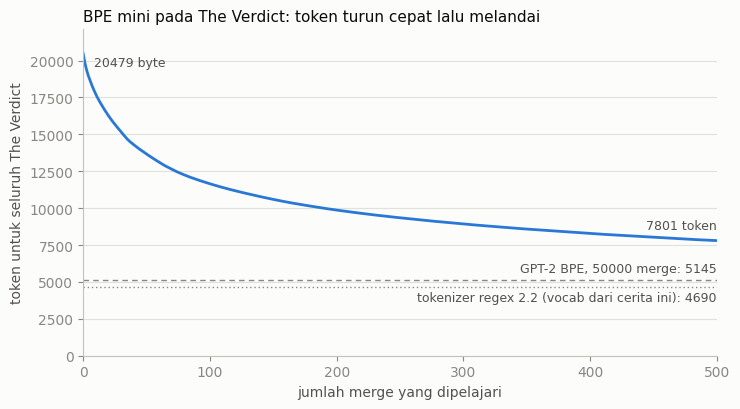

In [46]:
# Under the hood 2 (lanjutan) -- kurva kompresi BPE mini
import matplotlib.pyplot as plt

n_simple, n_gpt2 = len(preprocessed), len(tokenizer.encode(raw_text))
fig, ax = plt.subplots(figsize=(7.5, 4.2), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
ax.plot(range(len(curve)), curve, color="#2a78d6", linewidth=2)
ax.axhline(n_gpt2, color="#898781", linewidth=1, linestyle=(0, (4, 3)))
ax.text(len(curve) - 1, n_gpt2 + 300, f"GPT-2 BPE, 50000 merge: {n_gpt2}", ha="right", va="bottom",
        fontsize=9, color="#52514e")
ax.axhline(n_simple, color="#898781", linewidth=1, linestyle=(0, (1, 2)))
ax.text(len(curve) - 1, n_simple - 300, f"tokenizer regex 2.2 (vocab dari cerita ini): {n_simple}",
        ha="right", va="top", fontsize=9, color="#52514e")
ax.annotate(f"{curve[0]} byte", (0, curve[0]), xytext=(8, -2), textcoords="offset points",
            fontsize=9, color="#52514e", va="top")
ax.annotate(f"{curve[-1]} token", (len(curve) - 1, curve[-1]), xytext=(0, 8), textcoords="offset points",
            fontsize=9, color="#52514e", ha="right")
ax.set_xlabel("jumlah merge yang dipelajari", color="#52514e")
ax.set_ylabel("token untuk seluruh The Verdict", color="#52514e")
ax.set_title("BPE mini pada The Verdict: token turun cepat lalu melandai", loc="left", fontsize=11, color="#0b0b0b")
ax.set_xlim(0, len(curve) - 1)
ax.set_ylim(0, curve[0] * 1.08)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#898781")
plt.tight_layout()


Grafik ini memperlihatkan tarik-ulur ukuran vocabulary. Merge awal menangkap pasangan yang sangat sering, seperti `' t'`, `'he'`, dan `' the'`, sehingga setiap merge memangkas ratusan token. Makin ke kanan, pasangan yang tersisa makin jarang, dan kurvanya melandai: setiap merge tambahan menghemat makin sedikit. Garis putus-putus menandai GPT-2 di 5,145 token, yang dicapai dengan 50,000 merge.

Garis titik-titik, tokenizer regex di 4,690 token, berada di bawah GPT-2. Itu bukan tanda tokenizer regex lebih efisien. Vocabulary-nya dibangun dari cerita ini sendiri, sehingga setiap kata pasti menjadi satu token, dan ia membuang semua whitespace. GPT-2 harus memecah kata yang lebih jarang menjadi beberapa potongan, dan menyimpan setiap newline sebagai token tersendiri (baris terakhir output BPE mini tadi mencatat 164 token GPT-2 yang isinya hanya whitespace, sama dengan jumlah newline di cerita). Spasi biasa tidak menambah token, karena menempel di depan kata.

Ukuran vocabulary juga punya harga di sisi model. Setiap token di vocabulary mendapat satu baris di matriks embedding, yang kita bangun di 2.7. Untuk GPT-2 small dengan lebar embedding 768, vocabulary 50,257 berarti 50,257 x 768 = 38,597,376 parameter hanya untuk token embedding. Angka ini akan muncul lagi saat parameter model dihitung di Chapter 4.

## 2.6 Data sampling with a sliding window

Teks kita kini sudah berupa deretan token ID. Sebelum mengubahnya menjadi vektor, ada satu pertanyaan: contoh training seperti apa yang akan kita berikan ke model? LLM dilatih dengan *next-word prediction*: model menerima sepotong teks dan harus menebak token berikutnya, tanpa melihat apa pun sesudahnya. Pasangan input dan target untuk tugas ini bisa dipotong langsung dari teks, tanpa label buatan manusia, karena target-nya adalah teks itu sendiri yang digeser satu langkah.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.12.png" width="700">

**Figure 2.12** Delapan baris dari kalimat `LLMs learn to predict one word at a time`: setiap baris menambah satu kata ke input, dan target-nya adalah kata berikutnya. Sel-sel di bawah melakukan hal yang sama dengan token ID.

Langkah pertama: tokenisasi seluruh cerita dengan BPE.

In [47]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

enc_text = tokenizer.encode(raw_text)
print(len(enc_text))

5145


Cerita ini menjadi 5,145 token BPE, lebih banyak dari 4,690 token regex, padahal vocabulary GPT-2 44 kali lebih besar (50,257 dibanding 1,132). Alasannya sudah kita lihat di Under the hood 2: BPE memecah kata yang lebih jarang menjadi beberapa potongan dan menyimpan setiap newline sebagai token tersendiri. Rata-rata setiap token mewakili 20,479 / 5,145 = 3.98 karakter. Dan karena BPE lossless (Under the hood 1), ke-5,145 token ini mewakili teks persis seperti aslinya, bukan versi yang sudah dinormalisasi.

In [48]:
enc_sample = enc_text[50:]

In [49]:
context_size = 4

x = enc_sample[:context_size]
y = enc_sample[1:context_size+1]

print(f"x: {x}")
print(f"y:      {y}")

x: [290, 4920, 2241, 287]
y:      [4920, 2241, 287, 257]


Untuk contoh, buku membuang 50 token pertama (`enc_text[50:]`), karena menurut buku potongan sesudahnya sedikit lebih menarik untuk diperlihatkan. `x` berisi empat token pertama potongan itu, dan `y` adalah `x` yang digeser satu posisi: setiap elemen `y` adalah token yang harus ditebak sesudah elemen `x` di posisi yang sama. Spasi tambahan setelah `y:` di kode hanya untuk meratakan kedua baris.

In [50]:
for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]

    print(context, "---->", desired)

[290] ----> 4920
[290, 4920] ----> 2241
[290, 4920, 2241] ----> 287
[290, 4920, 2241, 287] ----> 257


Satu jendela berisi empat token ternyata memuat empat tugas tebakan sekaligus, dengan konteks 1, 2, 3, dan 4 token. Di kiri panah adalah apa yang dilihat model, di kanan token yang harus ia tebak. Jadi satu baris input-target sepanjang `n` memberi `n` contoh training, bukan satu. Inilah salah satu hal yang membuat training LLM efisien: di Chapter 5, loss dihitung di setiap posisi sekaligus.

In [51]:
for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]

    print(tokenizer.decode(context), "---->", tokenizer.decode([desired]))

 and ---->  established
 and established ---->  himself
 and established himself ---->  in
 and established himself in ---->  a


Dalam bentuk teks: dari `" and"`, model harus menebak `" established"`; dari `" and established"`, menebak `" himself"`; begitu seterusnya sampai `" a"`. Perhatikan juga spasi di depan setiap token. Token GPT-2 membawa spasi pembukanya sendiri, sehingga di output ada dua spasi sesudah panah: satu dari pemisah argumen `print`, satu lagi milik token.

Sekarang kita butuh pasangan seperti ini dalam jumlah besar. Alatnya adalah *data loader*: objek yang bisa diiterasi dan setiap kali mengembalikan input dan target sebagai tensor PyTorch. Satu tensor berisi input (teks yang dilihat model), tensor kedua berisi target (input yang digeser satu posisi).

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.13.png" width="700">

**Figure 2.13** Dua tensor sejajar: setiap baris `x` adalah satu konteks, dan baris `y` yang sama adalah konteks itu digeser satu token. Versi token ID-nya tercetak di bawah, mulai dari input `[40, 367, 2885, 1464]` dengan target `[367, 2885, 1464, 1807]`.

Implementasinya memakai dua kelas bawaan PyTorch: `Dataset`, yang menyimpan contoh-contoh, dan `DataLoader`, yang menyusunnya menjadi batch.

In [52]:
import torch
print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cpu


Versi PyTorch-nya sama dengan di Setup, 2.11.0 build khusus CPU. Listing di bab ini hanya memakai bagian PyTorch yang sudah lama stabil: `Dataset` dan `DataLoader` di bagian ini, lalu `nn.Embedding` dan `torch.arange` di 2.7 dan 2.8.

Listing 2.5, `GPTDatasetV1`, bekerja dalam dua langkah. Seluruh teks ditokenisasi sekali. Lalu sebuah jendela sepanjang `max_length` digeser sepanjang deretan token, setiap kali sejauh `stride` token. Di setiap posisi, jendela itu memotong satu baris input, dan jendela yang sama digeser satu token memotong baris target-nya.

Versi repo di bawah berbeda dari versi cetak buku dalam dua hal: `encode` dipanggil dengan `allowed_special={"<|endoftext|>"}`, dan ada `assert` yang memastikan teksnya lebih panjang dari `max_length`. Perbedaan pertama ternyata penting.

In [53]:
from torch.utils.data import Dataset, DataLoader


class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        # Tokenize the entire text
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})
        assert len(token_ids) > max_length, "Number of tokenized inputs must at least be equal to max_length+1"

        # Use a sliding window to chunk the book into overlapping sequences of max_length
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

### Errata #4 -- Listing 2.5 versi cetak crash pada teks yang mengandung `<|endoftext|>`

Di buku, `GPTDatasetV1` memanggil `tokenizer.encode(txt)` tanpa `allowed_special`. Secara bawaan, tiktoken menolak teks yang memuat string token khusus. Dengan The Verdict hal ini tidak terlihat, karena cerita itu tidak memuat `<|endoftext|>`. Padahal bagian 2.4 justru menganjurkan menyisipkan `<|endoftext|>` di antara dokumen. Sel berikut menjalankan kelas versi cetak apa adanya pada dua salinan cerita yang disambung sesuai anjuran itu. Seperti di Errata #2, versi repo disimpan dulu, dan traceback-nya dicetak dengan `traceback.print_exc()` supaya *Run all* tetap berlanjut.

In [54]:
# Errata #4 -- Listing 2.5 persis seperti tercetak di buku: encode tanpa allowed_special
import traceback
if "GPTDatasetV1_repo" not in globals():   # simpan versi repo sekali saja (aman bila sel diulang)
    GPTDatasetV1_repo = GPTDatasetV1

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []
        token_ids = tokenizer.encode(txt)
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))
    def __len__(self):
        return len(self.input_ids)
    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

two_docs = raw_text + " <|endoftext|> " + raw_text   # dua dokumen, dipisah sesuai anjuran 2.4
try:
    GPTDatasetV1(two_docs, tokenizer, max_length=4, stride=4)
except ValueError:
    traceback.print_exc()                           # traceback riil, dicetak agar Run all berlanjut


Traceback (most recent call last):
  File "/tmp/ipykernel_2251/669074787.py", line 23, in <cell line: 0>
    GPTDatasetV1(two_docs, tokenizer, max_length=4, stride=4)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_2251/669074787.py", line 10, in __init__
    token_ids = tokenizer.encode(txt)
  File "/usr/local/lib/python3.13/dist-packages/tiktoken/core.py", line 124, in encode
    raise_disallowed_special_token(match.group())
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/tiktoken/core.py", line 442, in raise_disallowed_special_token
    raise ValueError(
    ...<6 lines>...
    )
ValueError: Encountered text corresponding to disallowed special token '<|endoftext|>'.
If you want this text to be encoded as a special token, pass it to `allowed_special`, e.g. `allowed_special={'<|endoftext|>', ...}`.
If you want this text to be encoded as normal text, disable the check for this token by passing `disal

Tiktoken menolak dengan `ValueError`: teks memuat `<|endoftext|>`, dan secara bawaan semua token khusus dianggap terlarang (`disallowed_special="all"`). Pesan error-nya menawarkan dua arah. Yang pertama, memasukkan token itu ke `allowed_special` supaya di-encode sebagai token khusus, adalah yang dipakai repo. Yang kedua, mematikan pemeriksaan (misalnya dengan `disallowed_special=()`), juga menghilangkan crash, tapi akibatnya berbeda: pemisah dokumen di-encode sebagai deretan token teks biasa, dan model tidak pernah melihat ID 50256 sebagai pemisah. Kegagalan diam-diam seperti itu lebih buruk daripada crash. Sel berikut memulihkan versi repo, mengulang panggilan yang sama, dan membandingkan kedua arah itu.

In [55]:
# Koreksi Errata #4: pulihkan versi repo dan ulangi pada teks yang sama
GPTDatasetV1 = GPTDatasetV1_repo
ds_two = GPTDatasetV1(two_docs, tokenizer, max_length=4, stride=4)
flat = torch.cat(ds_two.input_ids).tolist()
as_text = tokenizer.encode(two_docs, disallowed_special=())     # alternatif yang salah, untuk pembanding
print("versi repo     : window", len(ds_two), "| ID 50256 di input:", flat.count(50256))
print("token two_docs : allowed_special", len(tokenizer.encode(two_docs, allowed_special={"<|endoftext|>"})),
      "| sebagai teks biasa", len(as_text), "| 50256 di versi teks biasa:", as_text.count(50256))
print("pemisah sebagai teks biasa:", [tokenizer.decode([i]) for i in tokenizer.encode("<|endoftext|>", disallowed_special=())])


versi repo     : window 2572 | ID 50256 di input: 1
token two_docs : allowed_special 10292 | sebagai teks biasa 10297 | 50256 di versi teks biasa: 0
pemisah sebagai teks biasa: ['<', '|', 'end', 'of', 'text', '|', '>']


Versi repo membangun 2,572 jendela dari dua salinan cerita, dan pemisahnya masuk sebagai satu token, ID 50256, yang muncul tepat sekali di input. Dengan `disallowed_special=()`, teks yang sama menjadi 10,297 token, tanpa satu pun ID 50256: string `<|endoftext|>` pecah menjadi tujuh potongan biasa (`'<', '|', 'end', 'of', 'text', '|', '>'`). Selisihnya dengan 10,292 hanya lima, bukan enam, karena di versi repo pemisah itu sudah memakan dua token: spasi di depannya menjadi token tersendiri (ID 220), lalu 50256. Pola yang sama sebenarnya sudah ada di output teks uji 2.5 (`..., 30, 220, 50256, 554, ...`), walaupun waktu itu belum kita perhatikan. Di versi teks biasa, spasi itu kemungkinan besar menempel ke potongan pertama, seperti spasi yang biasa menempel di depan kata, sehingga pemisahnya tetap tujuh token. Model akan melihat tanda baca dan potongan kata, bukan batas dokumen. Jadi cara itu bukan perbaikan; perbaikan yang benar adalah versi repo.

Hal ini relevan langsung untuk bab-bab berikutnya: Chapter 6 dan 7 memakai `<|endoftext|>` (ID 50256) sebagai token pengisi saat menyusun batch.

Listing 2.6 membungkus dataset ke dalam `DataLoader`. (Judul listing ini di buku tertulis "input-with pairs"; maksudnya pasangan input-target.) Beberapa detailnya perlu diperhatikan. Tokenizer GPT-2 dibuat di dalam fungsi. `drop_last=True` membuang batch terakhir kalau isinya kurang dari `batch_size`; menurut buku, batch yang terlalu kecil bisa membuat loss melonjak saat training. `num_workers` mengatur berapa proses CPU yang dipakai untuk menyiapkan data. Dan secara bawaan `shuffle=True`, jadi urutan jendela diacak.

In [56]:
def create_dataloader_v1(txt, batch_size=4, max_length=256,
                         stride=128, shuffle=True, drop_last=True,
                         num_workers=0):

    # Initialize the tokenizer
    tokenizer = tiktoken.get_encoding("gpt2")

    # Create dataset
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)

    # Create dataloader
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader

In [57]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

Kita uji dengan pengaturan terkecil yang masih mudah dibaca: `batch_size=1`, `max_length=4`, `stride=1`, dan `shuffle=False`.

In [58]:
dataloader = create_dataloader_v1(
    raw_text, batch_size=1, max_length=4, stride=1, shuffle=False
)

data_iter = iter(dataloader)
first_batch = next(data_iter)
print(first_batch)

[tensor([[  40,  367, 2885, 1464]]), tensor([[ 367, 2885, 1464, 1807]])]


`first_batch` berisi dua tensor berukuran `1 x 4`: input `[40, 367, 2885, 1464]` dan target `[367, 2885, 1464, 1807]`. Ini empat token pertama cerita, yang dibuka dengan "I HAD always", dan target-nya adalah input yang digeser satu posisi. Panjang 4 dipilih hanya supaya mudah dibaca; menurut buku, LLM umumnya dilatih dengan input minimal 256 token.

In [59]:
second_batch = next(data_iter)
print(second_batch)

[tensor([[ 367, 2885, 1464, 1807]]), tensor([[2885, 1464, 1807, 3619]])]


Batch kedua berisi input `[367, 2885, 1464, 1807]` dan target `[2885, 1464, 1807, 3619]`. Dengan `stride=1`, jendela hanya bergeser satu token, sehingga 3 dari 4 token input batch kedua sudah ada di batch pertama.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.14.png" width="700">

**Figure 2.14** Dua pengaturan stride pada kalimat contoh yang sama: dengan `stride=1`, input batch kedua hanya bergeser satu kata; dengan `stride=4`, batch kedua dimulai tepat setelah batch pertama berakhir. Kedua pengaturan dijalankan di sel-sel sekitar gambar ini.

### Exercise 2.2 -- Data loader dengan stride dan context size berbeda

Jarak geser jendela ternyata menentukan berapa kali setiap token dilihat saat training. Latihan kedua mengajak kita membangun intuisi itu: jalankan data loader dengan `max_length=2, stride=2` dan `max_length=8, stride=2`.

Sel-sel berikut diambil dari solusi resmi (`exercise-solutions.ipynb`, sel 16 sampai 18). Sel pertama mendefinisikan ulang `GPTDatasetV1` (sama dengan versi repo, tanpa `assert`), `tokenizer`, dan `raw_text`. Definisi ulang ini tidak mengubah hasil sel-sel bab sesudahnya, karena isinya sama dengan versi yang sudah ada; yang hilang hanya `assert` pemeriksa panjang teks. Fungsi `create_dataloader` di solusi tidak mengatur `shuffle` dan `drop_last`, jadi memakai nilai bawaan `DataLoader`: `shuffle=False` dan `drop_last=False`.

In [60]:
import tiktoken
import torch
from torch.utils.data import Dataset, DataLoader


class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        # Tokenize the entire text
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})

        # Use a sliding window to chunk the book into overlapping sequences of max_length
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]


def create_dataloader(txt, batch_size=4, max_length=256, stride=128):
    # Initialize the tokenizer
    tokenizer = tiktoken.get_encoding("gpt2")

    # Create dataset
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)

    # Create dataloader
    dataloader = DataLoader(dataset, batch_size=batch_size)

    return dataloader


with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

tokenizer = tiktoken.get_encoding("gpt2")
encoded_text = tokenizer.encode(raw_text)

In [61]:
dataloader = create_dataloader(raw_text, batch_size=4, max_length=2, stride=2)

for batch in dataloader:
    x, y = batch
    break

x

tensor([[  40,  367],
        [2885, 1464],
        [1807, 3619],
        [ 402,  271]])

Dengan `max_length=2, stride=2`, batch pertama berisi empat baris: `[40, 367]`, `[2885, 1464]`, `[1807, 3619]`, `[402, 271]`. Ini delapan token pertama cerita, dipotong menjadi pasangan berurutan. Karena stride sama dengan panjang jendela, tidak ada token yang terulang dan tidak ada yang terlewat.

In [62]:
dataloader = create_dataloader(raw_text, batch_size=4, max_length=8, stride=2)

for batch in dataloader:
    x, y = batch
    break

x

tensor([[   40,   367,  2885,  1464,  1807,  3619,   402,   271],
        [ 2885,  1464,  1807,  3619,   402,   271, 10899,  2138],
        [ 1807,  3619,   402,   271, 10899,  2138,   257,  7026],
        [  402,   271, 10899,  2138,   257,  7026, 15632,   438]])

Dengan `max_length=8, stride=2`, setiap baris hanya bergeser dua token dari baris sebelumnya: baris kedua dimulai dari `2885`, token ketiga di baris pertama. Akibatnya 6 dari 8 token di setiap baris (75%) sudah muncul di baris sebelumnya.

Dua batch ini hanya memperlihatkan empat baris pertama. Sel tambahan berikut menghitung akibatnya untuk seluruh dataset, dengan beberapa pengaturan lain sebagai pembanding.

In [63]:
# Sel tambahan (Exercise 2.2 dijawab dengan pengukuran): overlap, pemakaian, cakupan target
# Asumsi loader: create_dataloader_v1 dengan shuffle=False, drop_last=True
token_ids = tokenizer.encode(raw_text)
N = len(token_ids)
ex22 = {}
print(f"{N} token -> {N - 1} posisi target yang mungkin")
print(f"{'max_len':>7} {'stride':>6} {'batch':>5} | {'window':>6} {'overlap':>7} | {'batch':>5} {'dibuang':>7} "
      f"{'pakai':>6} | {'tercakup: semua window':>22} {'setelah drop_last':>17}")
for max_length, stride, batch_size in [(2, 2, 4), (8, 2, 4), (4, 1, 1), (4, 4, 8), (256, 128, 4), (4, 5, 8)]:
    starts = list(range(0, N - max_length, stride))           # loop yang sama dengan GPTDatasetV1
    kept = len(starts) // batch_size * batch_size              # window yang benar-benar diproses
    cover = lambda ss: len({p for s in ss for p in range(s + 1, s + max_length + 1)}) / (N - 1)
    row = {"win": len(starts), "drop": len(starts) - kept, "use": kept * max_length / (N - 1),
           "cov_all": cover(starts), "cov": cover(starts[:kept])}
    ex22[(max_length, stride, batch_size)] = row
    print(f"{max_length:>7} {stride:>6} {batch_size:>5} | {row['win']:>6} {max(0, max_length - stride) / max_length:>7.0%} | "
          f"{kept // batch_size:>5} {row['drop']:>7} {row['use']:>5.2f}x | {row['cov_all']:>22.2%} {row['cov']:>17.2%}")


5145 token -> 5144 posisi target yang mungkin
max_len stride batch | window overlap | batch dibuang  pakai | tercakup: semua window setelah drop_last
      2      2     4 |   2572      0% |   643       0  1.00x |                100.00%           100.00%
      8      2     4 |   2569     75% |   642       1  3.99x |                100.00%            99.96%
      4      1     1 |   5141     75% |  5141       0  4.00x |                100.00%           100.00%
      4      4     8 |   1286      0% |   160       6  1.00x |                100.00%            99.53%
    256    128     4 |     39     50% |     9       3  1.79x |                 99.53%            92.07%
      4      5     8 |   1029      0% |   128       5  0.80x |                 80.02%            79.63%


Pertanyaan latihan tadi, berapa kali setiap token dilihat saat training, dijawab oleh kolom `pakai`: rata-rata berapa kali setiap posisi target dilatih dalam satu *epoch*, yaitu satu putaran penuh atas data, dihitung dari jendela yang benar-benar diproses. Angka itu terutama ditentukan oleh `overlap`, porsi satu jendela yang terulang di jendela berikutnya. Kolom lainnya melengkapi gambaran: `window` adalah jumlah baris dataset, kolom `batch` pertama adalah ukuran batch dan yang kedua jumlah batch, `dibuang` adalah jendela sisa yang dibuang `drop_last=True`, dan dua kolom terakhir mencatat porsi posisi target yang tercakup sebelum dan sesudah pembuangan itu.

Kalau stride sama dengan panjang jendela (2/2 dan 4/4), tidak ada overlap, dan setiap target dilatih paling banyak sekali (`pakai` 1.00x). Inilah pengaturan yang menurut buku tidak melewatkan satu kata pun, dan memang jendela-jendelanya mencakup semua target. Hanya saja, di konfigurasi 4/4 dengan batch 8, `drop_last` membuang 6 jendela terakhir, sehingga cakupan per epoch 99.53%. Kalau stride lebih kecil dari jendela (8/2 dan 4/1), overlap-nya 75%, dan setiap target dilatih sekitar empat kali per epoch (3.99x dan 4.00x). Datanya seolah bertambah, padahal isinya sama; menurut buku, overlap seperti ini menaikkan risiko *overfitting*, yaitu model menghafal data training alih-alih mempelajari pola yang berlaku umum. Kalau stride lebih besar dari jendela (4/5, pembanding tambahan), satu dari setiap lima token tidak pernah menjadi target, dan cakupannya hanya 80.02%.

Baris 256/128 adalah pengaturan bawaan `create_dataloader_v1` untuk kedua argumen itu. Pada cerita sependek ini, ia hanya menghasilkan 39 jendela. Jendela terakhir berhenti sebelum ujung teks (cakupan 99.53%), lalu `drop_last` membuang 3 jendela lagi, sehingga hanya 92.07% target yang dilatih per epoch, rata-rata 1.79 kali.

Semua angka di tabel memakai `shuffle=False`, sehingga jendela yang dibuang selalu ekor yang sama, dan kehilangannya permanen. Dengan bawaan `create_dataloader_v1` (`shuffle=True`), jendela yang dibuang berganti setiap epoch: per epoch jumlah yang hilang sama, tapi lintas epoch semua jendela akhirnya terpakai. Solusi latihan sendiri (`drop_last=False`) tidak membuang jendela apa pun, sehingga cakupannya sama dengan kolom "semua window".

Contoh buku sejauh ini memakai batch berisi satu baris, sedangkan latihan 2.2 sudah memperlihatkan batch empat baris: beberapa jendela ditumpuk menjadi satu tensor. Ukuran batch adalah tarik-ulur. Menurut buku, batch kecil hemat memori, tapi update model jadi lebih fluktuatif, karena setiap update dihitung dari lebih sedikit contoh. Contoh buku berikut memakai `batch_size=8` dengan `max_length=4` dan `stride=4`. Karena stride sama dengan panjang jendela, jendela-jendelanya tidak saling tumpang tindih:

In [64]:
dataloader = create_dataloader_v1(raw_text, batch_size=8, max_length=4, stride=4, shuffle=False)

data_iter = iter(dataloader)
inputs, targets = next(data_iter)
print("Inputs:\n", inputs)
print("\nTargets:\n", targets)

Inputs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Targets:
 tensor([[  367,  2885,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   922],
        [ 5891,  1576,   438,   568],
        [  340,   373,   645,  1049],
        [ 5975,   284,   502,   284],
        [ 3285,   326,    11,   287]])


Kedua tensor berukuran `8 x 4`. Setiap baris adalah jendela 4 token yang tidak tumpang tindih: input baris berikutnya dimulai tepat sesudah input baris sebelumnya berakhir. Karena itu elemen terakhir target baris `i` selalu sama dengan elemen pertama input baris `i+1` (1807, 10899, 15632, ...). Target terakhir, `287`, adalah token ke-33 cerita: delapan baris kali empat token input, ditambah satu.

Ada juga ID yang muncul lebih dari sekali di batch ini, misalnya `284` di baris 6 (posisi 2) dan baris 7 (posisi 0), dengan baris dan posisi dihitung dari 0. Token kembar seperti ini akan kita pakai lagi untuk melihat apa yang terjadi pada token yang sama di posisi berbeda.

## 2.7 Creating token embeddings

Tinggal satu langkah lagi: token ID diubah menjadi vektor embedding. Isi vektor-vektor ini diacak di awal, lalu disetel selama training di Chapter 5. Kenapa harus vektor bilangan riil, bukan ID-nya langsung? GPT adalah jaringan saraf yang dilatih dengan *backpropagation*: gradien loss dihitung terhadap setiap bobot, lalu setiap bobot digeser sedikit ke arah yang menurunkan loss. Gradien hanya masuk akal untuk besaran yang kontinu, sedangkan ID hanyalah label. (Catatan buku di bagian ini merujuk ke "section B.4 in appendix A" untuk pengantar backpropagation; penomoran B.x milik appendix B, jadi rujukan itu salah ketik.)

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.15.png" width="700">

**Figure 2.15** Jalur persiapan input: teks, token, token ID, lalu embedding vector. Bagian ini mengerjakan langkah terakhir, dari token ID ke token embedding.

Kita mulai dari contoh mainan: empat token ID `[2, 3, 5, 1]`, vocabulary yang hanya berisi 6 kata (bukan 50,257), dan embedding berdimensi 3 (GPT-3 memakai 12,288). Seed 123 dipasang supaya hasilnya bisa dibandingkan dengan buku.

In [65]:
input_ids = torch.tensor([2, 3, 5, 1])

In [66]:
vocab_size = 6
output_dim = 3

torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

In [67]:
print(embedding_layer.weight)

Parameter containing:
tensor([[ 0.3374, -0.1778, -0.1690],
        [ 0.9178,  1.5810,  1.3010],
        [ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-1.1589,  0.3255, -0.6315],
        [-2.8400, -0.7849, -1.4096]], requires_grad=True)


Inilah isi embedding layer: matriks `6 x 3`, satu baris untuk setiap token di vocabulary dan satu kolom untuk setiap dimensi embedding. Ke-18 angkanya sama dengan buku sampai empat desimal. `nn.Embedding` mengisi bobotnya dengan angka dari distribusi normal standar, memakai generator bilangan acak CPU, dan dengan seed 123 generator itu memberi angka yang sama di PyTorch 2.11 run ini dan di versi yang dipakai buku. Keterangan `requires_grad=True` menandakan bahwa angka-angka ini adalah parameter yang akan diperbarui optimizer saat training.

In [68]:
print(embedding_layer(torch.tensor([3])))

tensor([[-0.4015,  0.9666, -1.1481]], grad_fn=<EmbeddingBackward0>)


Vektor untuk ID 3 adalah `[-0.4015, 0.9666, -1.1481]`, persis baris keempat matriks di atas (indeks 3, karena Python menghitung dari 0). Jadi embedding layer sebenarnya hanya melakukan *lookup*: ambil baris ke-ID dari matriks bobot. Keterangan `grad_fn=<EmbeddingBackward0>` menandakan operasi ini tercatat di graf autograd, sehingga gradien nanti bisa mengalir kembali ke baris yang diambil.

In [69]:
print(embedding_layer(input_ids))

tensor([[ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-2.8400, -0.7849, -1.4096],
        [ 0.9178,  1.5810,  1.3010]], grad_fn=<EmbeddingBackward0>)


Empat ID menghasilkan matriks `4 x 3`: baris 2, 3, 5, dan 1 dari matriks bobot, disusun sesuai urutan input.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.16.png" width="700">

**Figure 2.16** Lookup untuk input `[2, 3, 5, 1]` dari sel di atas: setiap ID memilih satu baris matriks `6 x 3`, dan baris-baris itu disusun sesuai urutan input.

Buku menyebut lookup ini setara dengan mengubah setiap ID menjadi vektor *one-hot* (vektor nol sepanjang vocabulary dengan angka 1 di posisi ID itu) lalu mengalikannya dengan bobot sebuah linear layer, hanya jauh lebih efisien. Kesetaraan inilah yang membuat embedding layer bisa diperlakukan sebagai layer biasa yang dilatih dengan backpropagation. Repo menunjukkannya di notebook pelengkap; Under the hood 3 mengukurnya langsung pada batch nyata dari 2.6.

### Under the hood 3 -- Lookup embedding identik dengan one-hot @ W, nilai maupun gradien

Ada tiga pertanyaan. Apakah `Embedding(ids)` dan `one_hot(ids) @ W` memberi hasil yang identik sampai bit terakhir? Apakah gradiennya terhadap `W` juga identik? Dan berapa harga versi one-hot? Ukurannya dibuat realistis: vocabulary 50,257, dimensi 256, dan batch `8 x 4` dari dataloader di 2.6. Semua angka acak di sel ini berasal dari `torch.Generator` lokal, sehingga generator global bab tidak tersentuh, dan embedding layer yang dibuat di 2.8 tetap sama seperti kalau sel ini tidak ada.

In [70]:
# Under the hood 3 -- embedding lookup == one-hot @ W (kode orisinal)
import time

V, D = 50257, 256
gen = torch.Generator().manual_seed(2)                    # RNG lokal
emb3 = torch.nn.Embedding.from_pretrained(torch.randn(V, D, generator=gen), freeze=False)
onehot = torch.nn.functional.one_hot(inputs, num_classes=V).float()    # batch 8x4 nyata dari 2.6

# (a) nilai
out_lookup = emb3(inputs)
out_matmul = onehot @ emb3.weight
dval = (out_lookup - out_matmul).abs().max().item()
print("(a) bentuk         :", tuple(out_lookup.shape), "==", tuple(out_matmul.shape), "| one-hot", tuple(onehot.shape))
print("    nilai identik  :", torch.equal(out_lookup, out_matmul), "| max |selisih| =", dval)

# (b) gradien terhadap W untuk loss sembarang
upstream = torch.randn(out_lookup.shape, generator=gen)
g_lookup, = torch.autograd.grad((emb3(inputs) * upstream).sum(), emb3.weight)
g_matmul, = torch.autograd.grad(((onehot @ emb3.weight) * upstream).sum(), emb3.weight)
dgrad = (g_lookup - g_matmul).abs().max().item()
rows = int((g_lookup.abs().sum(dim=1) > 0).sum())
print("(b) gradien identik:", torch.equal(g_lookup, g_matmul), "| max |selisih| =", dgrad,
      f"| baris W yang menerima gradien: {rows} dari {V} (ID unik di batch: {inputs.unique().numel()})")

# (c) biaya (timing spesifik mesin; terbaik dari 5 ulangan)
def best_ms(fn, number):
    best = float("inf")
    for _ in range(5):
        t0 = time.perf_counter()
        for _ in range(number):
            fn()
        best = min(best, (time.perf_counter() - t0) / number)
    return best * 1e3

timings = {}
with torch.no_grad():
    for B, T in [(8, 4), (8, 256)]:
        ids = torch.randint(0, V, (B, T), generator=gen)
        oh = torch.nn.functional.one_hot(ids, num_classes=V).float()
        timings[(B, T)] = (best_ms(lambda: emb3(ids), 20), best_ms(lambda: oh @ emb3.weight, 3))
        t_lookup, t_matmul = timings[(B, T)]
        print(f"(c) batch {B}x{T:<3}: lookup {t_lookup:.4f} ms | one-hot @ W {t_matmul:.2f} ms"
              f" (~{t_matmul / t_lookup:.0f}x) | tensor one-hot {oh.numel() * 4 / 1e6:.1f} MB")
        del oh
gb = 8 * 1024 * V * 4 / 1e9
print(f"    skala GPT-2 small (8 x 1024 token, V={V}): one-hot float32 {gb:.2f} GB"
      f" vs output embedding D=768 {8 * 1024 * 768 * 4 / 1e6:.1f} MB")
uth3 = {"dval": dval, "dgrad": dgrad, "t": timings, "gb": gb}


(a) bentuk         : (8, 4, 256) == (8, 4, 256) | one-hot (8, 4, 50257)
    nilai identik  : True | max |selisih| = 0.0
(b) gradien identik: True | max |selisih| = 0.0 | baris W yang menerima gradien: 29 dari 50257 (ID unik di batch: 29)
(c) batch 8x4  : lookup 0.0102 ms | one-hot @ W 15.13 ms (~1481x) | tensor one-hot 6.4 MB
(c) batch 8x256: lookup 0.2841 ms | one-hot @ W 903.63 ms (~3181x) | tensor one-hot 411.7 MB
    skala GPT-2 small (8 x 1024 token, V=50257): one-hot float32 1.65 GB vs output embedding D=768 25.2 MB


Jawaban pertama: identik, sampai bit terakhir. `torch.equal` bernilai `True` dan selisih maksimumnya 0.0, bukan sekadar "dekat". Ini masuk akal kalau kita lihat apa yang dihitung perkalian matriks itu. Setiap elemen hasilnya adalah `1 * W[id, j]` ditambah 50,256 suku `0 * W[k, j]`, dan menambahkan nol tidak mengubah apa pun, bahkan di floating point. Secara matematis, embedding layer adalah linear layer tanpa bias yang menerima input one-hot.

Gradiennya juga identik (selisih 0.0), jadi keduanya setara bukan hanya saat dipakai, tapi juga saat dilatih. Bentuk gradiennya pun menarik: hanya 29 dari 50,257 baris `W` yang menerima gradien, tepat sebanyak ID unik di batch (32 posisi, dengan 3 ID muncul dua kali, salah satunya `284` tadi). Baris untuk token yang tidak muncul di batch tidak menerima gradien sama sekali, sehingga token yang jarang muncul juga jarang mendapat sinyal belajar. Ini sisi lain dari masalah kata langka di Under the hood 1.

Bedanya ada di harga. Untuk batch `8 x 256`, lookup butuh 0.2841 ms, sedangkan perkalian one-hot 903.63 ms, sekitar 3,181 kali lebih lama (waktu terbaik dari lima ulangan), dan tensor one-hot-nya sendiri sudah 411.7 MB. Di batch kecil `8 x 4` pun selisihnya sudah lebih dari seribu kali. Angka waktu ini bergantung pada mesin, misalnya jumlah thread CPU (run ini hanya memakai satu), dan akan bergeser kalau sel dijalankan ulang; yang tetap adalah arahnya, yaitu lookup jauh lebih murah. Secara hitungan, setiap angka output versi one-hot butuh 50,257 perkalian dan penjumlahan, sedangkan lookup cukup menyalin satu angka. Rasio waktunya jauh lebih kecil dari 50,257, kemungkinan besar karena library perkalian matriks sangat efisien, sedangkan lookup sekecil ini didominasi ongkos pemanggilan fungsi.

Pada skala GPT-2 small (8 x 1,024 token per batch), satu batch one-hot butuh 1.65 GB hanya untuk input, sedangkan output embedding-nya 25.2 MB. Karena lookup menghitung operasi linear yang sama, hanya dengan cara yang jauh lebih hemat, ia bisa dilatih dengan backpropagation seperti layer lain.

## 2.8 Encoding word positions

Embedding token punya satu kekurangan: ia hanya bergantung pada ID. Token yang sama mendapat vektor yang sama di posisi mana pun, sehingga "dog" di awal kalimat dan "dog" di akhir kalimat tidak bisa dibedakan dari vektornya saja. Buku menambahkan bahwa self-attention, mekanisme yang dibangun di Chapter 3, juga tidak punya konsep posisi. Klaim kedua itu berlaku persis untuk attention tanpa *mask*. GPT memakai *causal mask*, yang membuat setiap token hanya bisa melihat token sebelumnya, dan mask itu sendiri sudah membawa sebagian sinyal urutan. Under the hood 4 di akhir bagian ini mengukur ketiganya: token embedding, attention tanpa mask, dan attention dengan causal mask.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.17.png" width="700">

**Figure 2.17** Input `[2, 3, 5, 2]`: ID 2 (`fox`) muncul di posisi pertama dan keempat dan mengambil baris matriks yang sama dua kali, sehingga vektornya kembar. Caption cetak buku menyebut ID 5 untuk kedua posisi itu; di gambar, ID 5 (`over`) hanya ada di posisi ketiga.

Jalan keluarnya adalah menambahkan sinyal posisi ke setiap vektor, dan ada dua desain. Pada *absolute positional embedding*, setiap indeks posisi (0, 1, 2, dan seterusnya) punya vektornya sendiri, dan vektor itu dijumlahkan dengan token embedding di posisi tersebut. Pada *relative positional embedding*, yang dikodekan adalah jarak antara pasangan token, bukan posisi mutlaknya; model yang memakainya tidak terikat pada indeks tertentu, sehingga lebih mudah dipakai pada teks yang lebih panjang dari teks training.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.18.png" width="700">

**Figure 2.18** Angka mainan: token embedding bernilai 1 di setiap dimensi, vektor posisi ke-k bernilai k.1, k.2, k.3, dan input embedding adalah jumlah keduanya (2.1, 2.2, 2.3 di posisi pertama).

GPT memakai desain absolute, dengan vektor posisi yang dipelajari selama training, bukan dihitung dengan rumus tetap seperti rumus sinus-kosinus di transformer orisinal. Sel-sel berikut membangunnya dengan ukuran yang lebih realistis: vocabulary BPE 50,257 dan lebar 256.

In [71]:
vocab_size = 50257
output_dim = 256

token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

Dataloader dari 2.6 dibuat ulang dengan `batch_size=8`, `max_length=4`, dan `stride=4`, lalu satu batch diambil.

In [72]:
max_length = 4
dataloader = create_dataloader_v1(
    raw_text, batch_size=8, max_length=max_length,
    stride=max_length, shuffle=False
)
data_iter = iter(dataloader)
inputs, targets = next(data_iter)

In [73]:
print("Token IDs:\n", inputs)
print("\nInputs shape:\n", inputs.shape)

Token IDs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Inputs shape:
 torch.Size([8, 4])


Ini batch yang sama dengan di 2.6, angka demi angka: `8 x 4`, yaitu 8 potongan teks yang masing-masing berisi 4 token.

In [74]:
token_embeddings = token_embedding_layer(inputs)
print(token_embeddings.shape)

# uncomment & execute the following line to see how the embeddings look like
# print(token_embeddings)

torch.Size([8, 4, 256])


Hasilnya `8 x 4 x 256`: setiap token ID di batch kini menjadi vektor 256 dimensi. Ke-32 token ID itu mengambil barisnya dari satu matriks berukuran 50,257 x 256, yaitu 12,865,792 parameter. Angka ini tepat sepertiga dari 38,597,376 parameter token embedding GPT-2 small yang kita hitung di akhir Under the hood 2, karena lebar 256 adalah sepertiga dari 768. Bobotnya masih acak, jadi angka-angkanya belum bermakna; yang penting di sini bentuknya. Acaknya pun tetap bisa diulang: layer ini dibuat tanpa seed baru, melanjutkan generator acak global yang terakhir di-reset oleh `torch.manual_seed(123)` di 2.7, dan Under the hood 3 yang dijalankan di antaranya tidak menyentuh generator itu.

In [75]:
context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)

# uncomment & execute the following line to see how the embedding layer weights look like
# print(pos_embedding_layer.weight)

In [76]:
pos_embeddings = pos_embedding_layer(torch.arange(max_length))
print(pos_embeddings.shape)

# uncomment & execute the following line to see how the embeddings look like
# print(pos_embeddings)

torch.Size([4, 256])


`4 x 256`: satu vektor untuk setiap posisi 0 sampai 3. Input-nya, `torch.arange(max_length)`, adalah deretan `0, 1, 2, 3`, jadi embedding posisi juga hanya sebuah lookup, kali ini berdasarkan nomor posisi, bukan token ID. `context_length` adalah panjang input maksimum yang didukung model, di sini sama dengan `max_length`; teks yang lebih panjang harus dipotong.

In [77]:
input_embeddings = token_embeddings + pos_embeddings
print(input_embeddings.shape)

# uncomment & execute the following line to see how the embeddings look like
# print(input_embeddings)

torch.Size([8, 4, 256])


Hasil akhirnya `8 x 4 x 256`. Penjumlahan `[8, 4, 256] + [4, 256]` memakai *broadcasting* PyTorch: tensor posisi `4 x 256` ditambahkan ke masing-masing dari 8 sampel, sehingga token ke-`j` di setiap sampel mendapat vektor posisi ke-`j` yang sama. Inilah input embedding yang siap diproses modul utama LLM, mulai di Chapter 3.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/02.Chapter02/figure2.19.png" width="700">

**Figure 2.19** Ringkasan bab dalam satu gambar: teks, token, token ID, token embedding ditambah positional embedding, lalu input embedding. Versi tensornya adalah `input_embeddings` berukuran `8 x 4 x 256` di sel di atas.

Apakah tambahan vektor posisi ini benar-benar mengubah apa yang bisa dilihat model? Itulah yang diuji di bagian terakhir.

### Under the hood 4 -- Posisi, attention tanpa mask, dan causal mask

Klaim di awal 2.8 bisa diuji dengan *self-attention* versi mini. Self-attention, yang dibangun lengkap di Chapter 3, membuat output setiap token menjadi campuran berbobot dari vektor token-token yang boleh ia lihat, dengan bobot yang dihitung dari kecocokan antarvektor. Versi mini di sini hanya punya satu head dan satu lapis, dengan bobot acak dari generator lokal dan tanpa training.

Pengukurannya ada tiga, dan di output diberi label (a) sampai (c). Yang pertama memakai token kembar di batch nyata, misalnya `284` di baris 6 (posisi 2) dan baris 7 (posisi 0), dan membandingkan vektornya sebelum dan sesudah positional embedding ditambahkan. Yang kedua menjalankan attention tanpa mask pada `" man bites dog."` dan `" dog bites man."`, tanpa dan dengan positional embedding. Kedua kalimat punya token yang persis sama dengan urutan berbeda, padahal maknanya jelas berbeda; apakah output-nya berbeda lebih dari sekadar urutan baris yang tertukar? Yang ketiga mengulang pasangan kalimat itu dengan causal mask (token `i` hanya melihat token `0` sampai `i`, seperti di GPT), tanpa positional embedding.

In [78]:
# Under the hood 4 -- posisi, attention tanpa mask, dan causal mask (kode orisinal)
# (a) token kembar di batch nyata: ID sama, posisi berbeda
twins = []
for (r1, c1), (r2, c2) in [((6, 2), (7, 0)), ((2, 2), (3, 3)), ((3, 1), (4, 3))]:
    tid = inputs[r1, c1].item()
    assert tid == inputs[r2, c2].item()
    d_tok = (token_embeddings[r1, c1] - token_embeddings[r2, c2]).abs().max().item()
    d_inp = (input_embeddings[r1, c1] - input_embeddings[r2, c2]).abs().max().item()
    twins.append((tid, d_tok, d_inp))
    print(f"(a) ID {tid:>4} {tokenizer.decode([tid])!r:>6} di posisi {c1} dan {c2}:"
          f" selisih token emb {d_tok:.4f} | selisih input emb {d_inp:.4f}")

# (b), (c) attention mini satu head pada dua kalimat yang hanya berbeda urutan
def self_attention(X, W_q, W_k, W_v, causal=False):
    Q, K, V = X @ W_q, X @ W_k, X @ W_v
    scores = Q @ K.T / K.shape[-1] ** 0.5
    if causal:                                     # token i hanya melihat token 0..i
        future = torch.triu(torch.ones_like(scores, dtype=torch.bool), diagonal=1)
        scores = scores.masked_fill(future, float("-inf"))
    return torch.softmax(scores, dim=-1) @ V

gen4 = torch.Generator().manual_seed(4)             # RNG lokal
W_q, W_k, W_v = (torch.randn(output_dim, output_dim, generator=gen4) / output_dim ** 0.5 for _ in range(3))
s1, s2 = " man bites dog.", " dog bites man."
ids1, ids2 = torch.tensor(tokenizer.encode(s1)), torch.tensor(tokenizer.encode(s2))
perm = [ids1.tolist().index(t) for t in ids2.tolist()]     # ids2 == ids1[perm]
with torch.no_grad():
    X1, X2 = token_embedding_layer(ids1), token_embedding_layer(ids2)
    P = pos_embedding_layer(torch.arange(context_length))
    A1, A2 = self_attention(X1, W_q, W_k, W_v), self_attention(X2, W_q, W_k, W_v)
    B1, B2 = self_attention(X1 + P, W_q, W_k, W_v), self_attention(X2 + P, W_q, W_k, W_v)
    C1, C2 = self_attention(X1, W_q, W_k, W_v, causal=True), self_attention(X2, W_q, W_k, W_v, causal=True)
uth4 = {"nopos": (A2 - A1[perm]).abs().max().item(), "pos": (B2 - B1[perm]).abs().max().item(),
        "pool_nopos": (A1.mean(0) - A2.mean(0)).abs().max().item(),
        "pool_pos": (B1.mean(0) - B2.mean(0)).abs().max().item(), "scale": B1.abs().mean().item(),
        "causal": (C2 - C1[perm]).abs().max().item(), "causal_last": (C2[-1] - C1[-1]).abs().max().item()}
print(f"(b) {s1!r} -> {ids1.tolist()} | {s2!r} -> {ids2.tolist()} | ids2 == ids1[{perm}]:",
      torch.equal(ids2, ids1[perm]))
print(f"    tanpa mask, tanpa posisi : max|A2 - A1[perm]| = {uth4['nopos']:.2e}"
      f" | selisih rata-rata output = {uth4['pool_nopos']:.2e}")
print(f"    tanpa mask, dengan posisi: max|B2 - B1[perm]| = {uth4['pos']:.2f}"
      f" | selisih rata-rata output = {uth4['pool_pos']:.2f} (skala: rata-rata |B1| = {uth4['scale']:.2f})")
print(f"(c) causal, tanpa posisi     : max|C2 - C1[perm]| = {uth4['causal']:.2f}"
      f" | posisi terakhir max|C2[-1] - C1[-1]| = {uth4['causal_last']:.2e}")


(a) ID  284  ' to' di posisi 2 dan 0: selisih token emb 0.0000 | selisih input emb 4.0155
(a) ID  257   ' a' di posisi 2 dan 3: selisih token emb 0.0000 | selisih input emb 4.8434
(a) ID  438   '--' di posisi 1 dan 3: selisih token emb 0.0000 | selisih input emb 4.6180
(b) ' man bites dog.' -> [582, 26081, 3290, 13] | ' dog bites man.' -> [3290, 26081, 582, 13] | ids2 == ids1[[2, 1, 0, 3]]: True
    tanpa mask, tanpa posisi : max|A2 - A1[perm]| = 2.38e-07 | selisih rata-rata output = 1.19e-07
    tanpa mask, dengan posisi: max|B2 - B1[perm]| = 4.60 | selisih rata-rata output = 1.07 (skala: rata-rata |B1| = 0.83)
(c) causal, tanpa posisi     : max|C2 - C1[perm]| = 3.98 | posisi terakhir max|C2[-1] - C1[-1]| = 1.19e-07


Token embedding memang buta posisi. Untuk ketiga pasang token kembar (`' to'` = 284, `' a'` = 257, `'--'` = 438), selisih token embedding-nya tepat 0.0000: vektornya identik, seperti di Figure 2.17. Begitu positional embedding ditambahkan, selisihnya menjadi 4.0155 sampai 4.8434, karena setiap posisi menyumbang vektor yang berbeda. Input embedding tidak lagi buta posisi.

Attention tanpa mask ternyata sama butanya. Tanpa posisi, output untuk `" dog bites man."` sama dengan output `" man bites dog."` yang barisnya ditukar mengikuti urutan token, dengan selisih maksimum 2.38e-07, yaitu sisa pembulatan float32, bukan perbedaan sungguhan. Rata-rata output, ringkasan yang tidak peduli urutan, berbeda hanya 1.19e-07. Inilah sifat attention tanpa mask yang disebut *permutation equivariance*: kalau baris input dipermutasi dengan matriks permutasi $\Pi$, output-nya ikut dipermutasi dengan cara yang sama, $\text{Attn}(\Pi X) = \Pi\,\text{Attn}(X)$. Urutan input hanya mengacak urutan baris output, dan siapa menggigit siapa tidak bisa dibedakan. Dengan positional embedding (yang masih acak, belum dilatih), selisihnya melonjak ke 4.60, dan rata-rata output berbeda 1.07, pada skala nilai output sekitar 0.83.

Causal mask memecah simetri itu, tapi hanya sebagian. Dengan mask dan tanpa positional embedding, selisih terhadap versi yang dipermutasi menjadi 3.98, karena token yang sama kini melihat awalan yang berbeda: `" dog"` di awal `" dog bites man."` hanya bisa melihat dirinya sendiri, sedangkan `" dog"` di `" man bites dog."` juga melihat `" man"` dan `" bites"`. Tapi mask hanya menentukan token *mana saja* yang mendahului, bukan urutannya. Di posisi terakhir, kedua kalimat melihat himpunan token yang sama, dan output-nya identik sampai 1.19e-07. Untuk satu lapis attention causal, output di posisi `i` bergantung pada token di posisi `i` dan himpunan token `0` sampai `i`, tanpa urutan di dalam himpunan itu.

Eksperimen ini kecil: satu head, satu lapis, bobot acak, satu pasang kalimat 4 token, tanpa training. Ia memperlihatkan permutation equivariance attention tanpa mask dan memperlihatkan bahwa causal mask hanya memecahnya sebagian. Ia tidak mengukur seberapa banyak informasi posisi yang bisa dipelajari model causal berlapis-lapis tanpa positional embedding, jadi hasilnya tidak bisa digeneralisasi ke model GPT di Chapter 3 dan 4. Yang pasti, GPT tetap menambahkan positional embedding eksplisit sebelum blok attention, persis seperti yang kita lakukan di 2.8.

## Summary

Bab ini membangun jalur input LLM dari teks mentah sampai tensor yang siap masuk ke attention, dan hampir di setiap langkahnya ada keputusan desain yang ternyata penting.

Tokenisasi dimulai dengan regex sederhana yang memotong di whitespace dan tanda baca. The Verdict menjadi 4,690 token dengan vocabulary 1,130 token unik, dan tokenizer itu bekerja selama setiap kata di teks yang di-encode sudah ada di vocabulary tersebut. Begitu bertemu `Hello`, ia berhenti dengan `KeyError`. Token khusus `<|unk|>` membuatnya tidak pernah berhenti lagi, tapi dengan harga: semua kata baru dipetakan ke satu ID yang sama. Dan karena whitespace dibuang sejak awal, decode tokenizer ini tidak bisa dijamin mengembalikan teks asli: di seluruh cerita, ke-164 newline hilang dan 94 dari 97 `--` kembali berspasi. Bahkan di bagian akhir cerita yang sama, kira-kira satu dari delapan token tidak dikenal oleh vocabulary yang dibangun dari bagian awalnya.

Byte pair encoding menyelesaikan masalah itu dengan cara yang berbeda: kata apa pun dirakit dari potongan yang dikenal, sampai ke byte tunggal, dan spasi disimpan di dalam token. `someunknownPlace` menjadi `' some' + 'unknown' + 'Place'`, `"Akwirw ier"` menjadi enam potongan, dan decode GPT-2 mengembalikan cerita persis seperti aslinya. BPE mini yang kita latih pada satu cerpen sudah mengulang awal tabel merge GPT-2, dimulai dari `' t'`. Harganya ada di panjang deretan: kalimat Indonesia di Under the hood 1 butuh 29 token BPE, sedangkan kalimat Inggris dengan isi yang sama hanya 14. Harga lain ada di sisi model: setiap token di vocabulary berarti satu baris lagi di matriks embedding.

Contoh training dipotong langsung dari teks dengan jendela geser. Target adalah input yang digeser satu token, dan satu jendela berisi `n` token memberi `n` tebakan sekaligus. Jarak geser menentukan berapa kali setiap token dilatih: stride yang sama dengan panjang jendela melatih setiap target paling banyak sekali. Stride yang lebih kecil mengulang setiap target kira-kira sebanyak panjang jendela dibagi stride: misalnya dengan jendela 8 dan stride 2, atau jendela 4 dan stride 1, sekitar empat kali per epoch.

Token ID lalu diubah menjadi vektor lewat embedding layer, yang tidak lain adalah lookup baris matriks: identik sampai bit terakhir dengan perkalian one-hot, untuk nilai maupun gradien, tapi jauh lebih cepat (di run ini ribuan kali). Karena lookup ini tidak tahu posisi, vektor posisi ditambahkan. Attention mini di Under the hood 4 memperlihatkan apa yang hilang tanpa vektor itu, setidaknya untuk satu lapis attention dengan bobot acak: tanpa mask dan tanpa posisi, `" man bites dog."` dan `" dog bites man."` hanya menghasilkan baris yang ditukar urutannya; causal mask membedakannya sebagian; positional embedding membuat urutan terlihat. Hasil akhir bab ini adalah tensor input `8 x 4 x 256`.

Sepanjang bab, ada empat tempat yang di buku tidak cocok dengan hasil kodenya. Dua di antaranya membuat kode cetak gagal: regex `encode` di listing 2.3 yang tidak memuat `:` dan `;` (Errata #2), dan `GPTDatasetV1` di listing 2.5 yang menolak `<|endoftext|>` (Errata #4). Satu lagi adalah output tiktoken di buku yang berasal dari teks berbeda satu spasi dari kodenya (Errata #3), ditambah satu catatan kecil tentang `raw_text[:99]` (Errata #1). Arah sebaliknya juga ada: sel pencetak versi tiktoken di repo gagal di skrip Python biasa, dan baru jalan kalau `importlib.metadata` sudah dimuat, seperti di kernel Jupyter.

Chapter 3 membangun self-attention, dari versi tanpa mask sampai multi-head attention dengan causal mask, untuk mengolah input embedding berbentuk seperti `input_embeddings` tadi; bab itu sendiri mulai dari contoh kecil, satu kalimat 6 token dengan embedding 3 dimensi. Under the hood 4 sudah memberi gambaran awal tentang apa yang bisa dan tidak bisa dilihat attention tanpa vektor posisi.

Semua output di notebook ini berasal dari satu kali run di Google Colab dengan PyTorch build CPU (Linux x86_64, Python 3.13.16, PyTorch 2.11.0+cpu, tiktoken 0.14.0). Kode bab diambil dari repo resmi pada commit `cdbd33e`. Angka dari buku, dari output yang tersimpan di repo, dan dari paper GPT-2 selalu disebut sumbernya di teks.